- Your Full Name: Priyanka Bolem
- Your Uplevel Email Address: priyankabolem@gmail.com
- Name of the Problem Statement of Submission: Lending Club Loan Approval: Implement a machine learning solution that automates the loan approval process, improving accuracy and efficiency.

# Lending Club Loan Approval System

## Business Background

Lending Club is a peer-to-peer lending company where individuals can borrow loans, and investors can fund those loans. Lending Club was founded in 2006 by Renaud Laplanche as a peer-to-peer (P2P) lending platform in San Francisco. It was one of the pioneers in the online lending space, where individual borrowers could obtain loans, and individual or institutional investors could invest in these loans to earn interest. The platform allowed for a more direct connection between lenders and borrowers, bypassing traditional banking intermediaries.

Read more here https://en.wikipedia.org/wiki/LendingClub

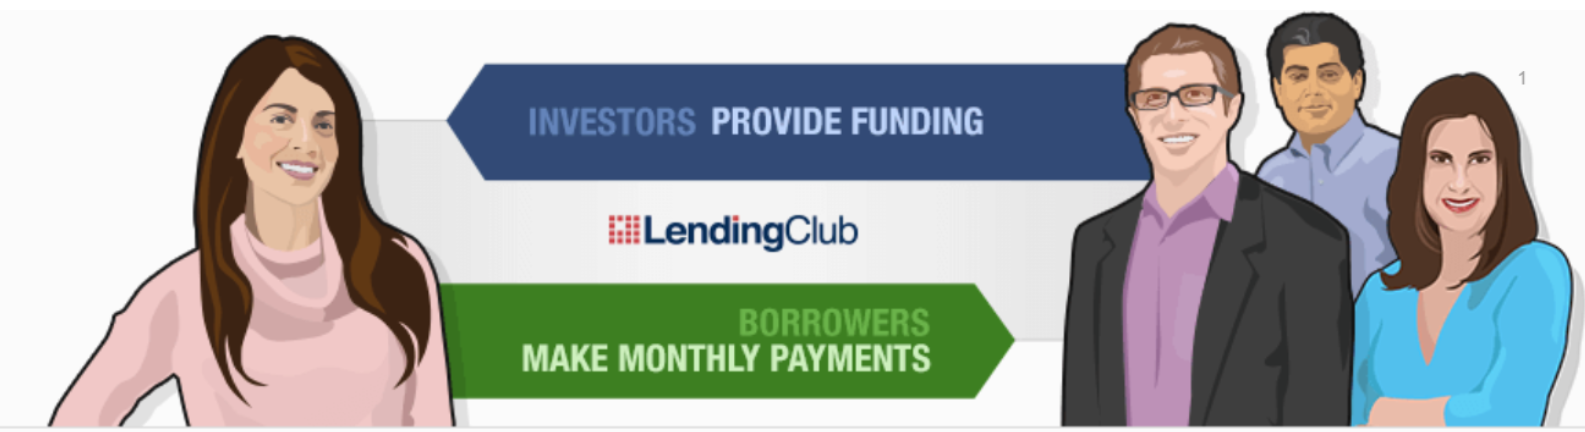

## Problem Statement

Now, whenever *Lending Club* approves a loan, there are two ways in which it is at risk:
- If LC approves a loan and the borrower fails to repay it on time
- If LC rejects a loan despite the borrower being capable of repaying the loan

Defaulting on loans can lead to significant financial losses for both the platform and investors. Similarly, not providing loans to credit-worthy customers can lead to missing out on potential revenue and profits. Therefore, a robust loan approval system is the need of the hour.

In the current loan approval process, underwriters evaluate loan applications by manually reviewing credit scores, income, debt, etc. and then, based on several parameters, either approve or reject a loan. This process is time-consuming and prone to errors.

Hence, Lending Club wants to build a loan approval system using Machine Learning models to automatically assess whether a given loan is likely to be repaid or whether the borrower is likely to default.

This is where you come in! As a budding data scientist, your goal is to help out Lending Club in creating this ML model that helps them predict whether a loan is likely to default or not.

## Data Understanding

You have been provided with around 38k loan application data from the Lending Club's website. The different columns and their description are mentioned below:

| Column Name         | Description                                                                                                                                                    |
|---------------------|----------------------------------------------------------------------------------------------------------------------------------------------------------------|
| id                  | A unique LC assigned ID for the loan listing. *(Integer)*                                                                                                       |
| member_id           | A unique LC assigned ID for the borrower member. *(Integer)*                                                                                                    |
| loan_amnt           | The listed amount of the loan applied for by the borrower. If at some point the credit department reduces the loan amount, it will be reflected in this value. *(Float)* |
| term                | The number of payments on the loan. Values are in months and can be either 36 or 60. *(Integer)*                                                                 |
| int_rate            | Interest rate on the loan. *(Float)*                                                                                                                            |
| installment         | The monthly payment owed by the borrower if the loan originates. *(Float)*                                                                                       |
| grade               | LC assigned loan grade. *(Categorical/String)*                                                                                                                  |
| sub_grade           | LC assigned loan subgrade. *(Categorical/String)*                                                                                                               |
| emp_length          | Employment length in years. Possible values are between 0 and 10, where 0 means less than one year and 10 means ten or more years. *(Integer)*                   |
| home_ownership      | The home ownership status provided by the borrower during registration. Values are: RENT, OWN, MORTGAGE, OTHER. *(Categorical/String)*                           |
| annual_inc          | The self-reported annual income provided by the borrower during registration. *(Float)*                                                                         |
| verification_status | Indicates if income was verified by LC, not verified, or if the income source was verified. *(Categorical/String)*                                               |
| purpose             | A category provided by the borrower for the loan request. *(Categorical/String)*                                                                                |
| dti                 | A ratio calculated using the borrower’s total monthly debt payments (excluding mortgage and the requested LC loan), divided by the borrower’s self-reported income. *(Float)* |
| delinq_2yrs         | The number of 30+ days past-due incidences of delinquency in the borrower's credit file for the past 2 years. *(Integer)*                                         |
| inq_last_6mths      | The number of inquiries in the past 6 months (excluding auto and mortgage inquiries). *(Integer)*                                                                |
| open_acc            | The number of open credit lines in the borrower's credit file. *(Integer)*                                                                                       |
| pub_rec             | Number of derogatory public records. *(Integer)*                                                                                                                |
| revol_bal           | Total credit revolving balance. *(Float)*                                                                                                                       |
| revol_util          | Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit. *(Float)*                             |
| total_acc           | The total number of credit lines currently in the borrower's credit file. *(Integer)*                                                                            |
| last_pymnt_amnt     | Last total payment amount received. *(Float)*                                                                                                                   |
| loan_status         | Current status of the loan. *(Categorical/String)*                                                                 
                  |

...

## Starter Code

### Necessary Imports

In [ ]:
# Import the neccesary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.metrics import roc_curve, precision_recall_curve, auc
from imblearn.over_sampling import SMOTE

In [ ]:
pd.set_option('display.max_columns', None)
import warnings
# Suppress all warnings
warnings.filterwarnings('ignore')

### Data Loading

In [ ]:
## Load the dataset
df = pd.read_csv('loans.csv')

In [ ]:
## Observe the first few rows
## Do you observe any issues? - There are numeric and objective type colums are there.
display(df.head())

,id,member_id,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,purpose,dti,delinq_2yrs,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,last_pymnt_amnt,loan_status
0,1077501,1296599.0,5000.0,36 months,10.65%,162.87,B,B2,10+ years,RENT,24000.0,Verified,credit_card,27.65,0.0,1.0,3.0,0.0,13648.0,83.7%,9.0,171.62,Fully Paid
1,1077430,1314167.0,2500.0,60 months,15.27%,59.83,C,C4,< 1 year,RENT,30000.0,Source Verified,car,1.00,0.0,5.0,3.0,0.0,1687.0,9.4%,4.0,119.66,Charged Off
2,1077175,1313524.0,2400.0,36 months,15.96%,84.33,C,C5,10+ years,RENT,12252.0,Not Verified,small_business,8.72,0.0,2.0,2.0,0.0,2956.0,98.5%,10.0,649.91,Fully Paid
3,1076863,1277178.0,10000.0,36 months,13.49%,339.31,C,C1,10+ years,RENT,49200.0,Source Verified,other,20.00,0.0,1.0,10.0,0.0,5598.0,21%,37.0,357.48,Fully Paid
4,1075269,1311441.0,5000.0,36 months,7.90%,156.46,A,A4,3 years,RENT,36000.0,Source Verified,wedding,11.20,0.0,3.0,9.0,0.0,7963.0,28.3%,12.0,161.03,Fully Paid


In [ ]:
## Check the dataframe structure - datatypes and number of non-null rows
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38770 entries, 0 to 38769
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   38770 non-null  int64  
 1   member_id            38770 non-null  float64
 2   loan_amnt            38770 non-null  float64
 3   term                 38770 non-null  object 
 4   int_rate             38770 non-null  object 
 5   installment          38770 non-null  float64
 6   grade                38770 non-null  object 
 7   sub_grade            38770 non-null  object 
 8   emp_length           37734 non-null  object 
 9   home_ownership       38770 non-null  object 
 10  annual_inc           38770 non-null  float64
 11  verification_status  38770 non-null  object 
 12  purpose              38770 non-null  object 
 13  dti                  38770 non-null  float64
 14  delinq_2yrs          38770 non-null  float64
 15  inq_last_6mths       38770 non-null 

Based on above info get to know that there is no null values and Our dataset consists of 13 numeric, 10 categorical values

In [ ]:
## Check the shape
print("Dataset shape:", df.shape)
print("\nSample of the dataset:")
print(df.head())

Dataset shape: (38770, 23)

Sample of the dataset:
        id  member_id  loan_amnt        term int_rate  installment grade  \
0  1077501  1296599.0     5000.0   36 months   10.65%       162.87     B   
1  1077430  1314167.0     2500.0   60 months   15.27%        59.83     C   
2  1077175  1313524.0     2400.0   36 months   15.96%        84.33     C   
3  1076863  1277178.0    10000.0   36 months   13.49%       339.31     C   
4  1075269  1311441.0     5000.0   36 months    7.90%       156.46     A   

  sub_grade emp_length home_ownership  annual_inc verification_status  \
0        B2  10+ years           RENT     24000.0            Verified   
1        C4   < 1 year           RENT     30000.0     Source Verified   
2        C5  10+ years           RENT     12252.0        Not Verified   
3        C1  10+ years           RENT     49200.0     Source Verified   
4        A4    3 years           RENT     36000.0     Source Verified   

          purpose    dti  delinq_2yrs  inq_last_6mths

In [ ]:
## Check the missing values across the columns
# df.isnull().sum()

print("\nMissing values per column:")
missing_values = df.isnull().sum()
missing_values = missing_values[missing_values > 0].sort_values(ascending=False)
print(missing_values)


Missing values per column:
emp_length    1036
revol_util      50
dtype: int64


By checking isnull().sum(), we get to know that there is missing values in emp_length and revol_util

In [ ]:
# checking summary of the dataset
print("\nDataset description:")
# print(df.describe())
df.describe().T


Dataset description:


,count,mean,std,min,25%,50%,75%,max
id,38770.0,676995.973072,209022.602925,54734.00,512703.2500,657993.50,828720.25,1077501.00
member_id,38770.0,843089.188367,264134.540029,70699.00,661910.0000,841092.00,1037009.50,1314167.00
loan_amnt,38770.0,11069.122388,7362.292600,500.00,5325.0000,9737.50,15000.00,35000.00
installment,38770.0,322.629489,208.592815,15.69,165.7400,278.15,426.10,1305.19
annual_inc,38770.0,68800.252230,64161.315787,4000.00,40000.0000,58923.50,82000.00,6000000.00
dti,38770.0,13.276704,6.676355,0.00,8.1300,13.37,18.56,29.99
delinq_2yrs,38770.0,0.146660,0.492197,0.00,0.0000,0.00,0.00,11.00
inq_last_6mths,38770.0,0.871473,1.071444,0.00,0.0000,1.00,1.00,8.00
open_acc,38770.0,9.278850,4.401871,2.00,6.0000,9.00,12.00,44.00
pub_rec,38770.0,0.055404,0.237727,0.00,0.0000,0.00,0.00,4.00


#### Observations

- Document your observations

From our initial exploration of the dataset, we got a good understanding of its structure, basic statistics, and areas that need attention. The dataset contains various details about loans, such as loan amount, interest rate, credit grade, and employment length.

One key observation is that some columns, like ‘emp_length’ (employment length) and ‘revol_util’ (revolving credit utilization), have missing values that need to be handled.

Additionally, the ‘loan_status’ column, which is our target variable, indicates whether a loan was fully paid or charged off. This will be crucial for our analysis in determining factors that contribute to loan repayment success or failure.

#Checking for distribution of data and plotting it

In [ ]:
# df_cols = df.drop(df.dtypes=='object')
df_cols = df.select_dtypes(exclude=['object'])

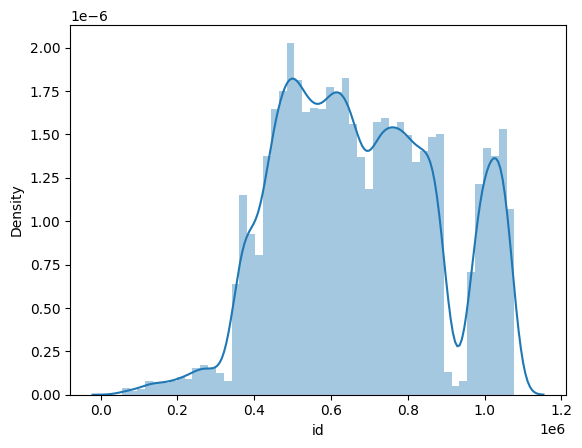

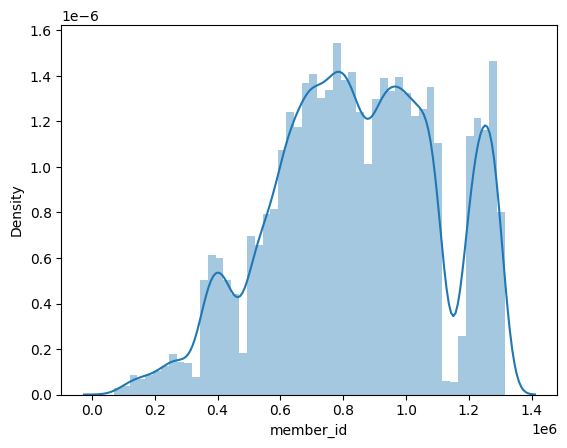

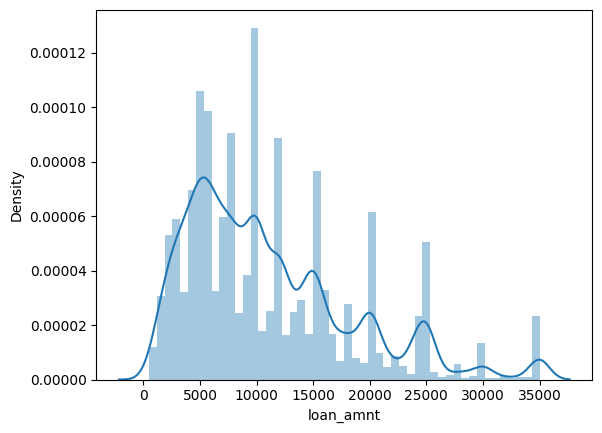

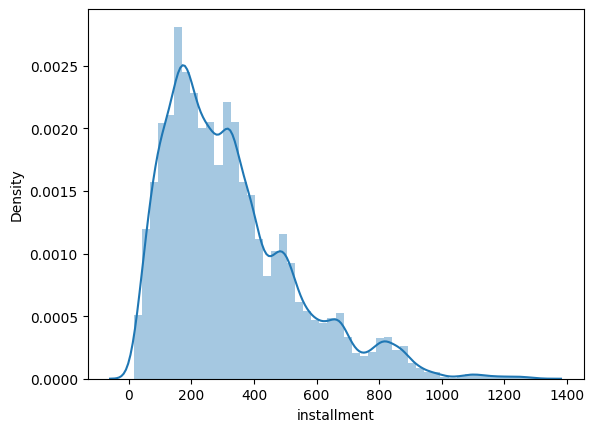

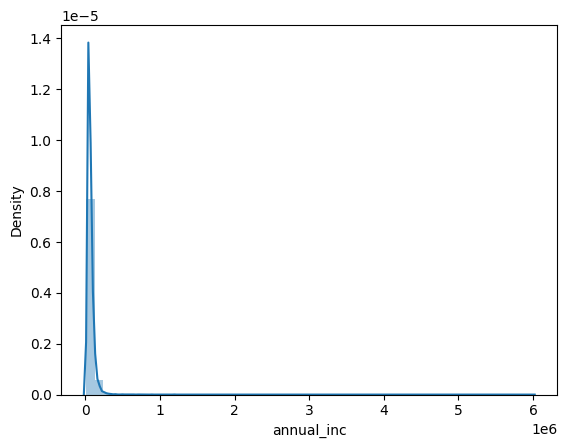

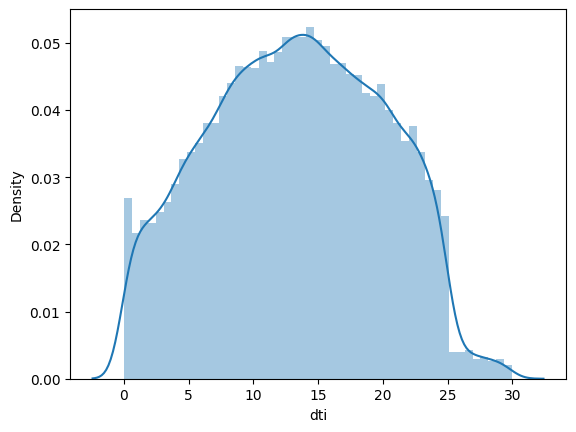

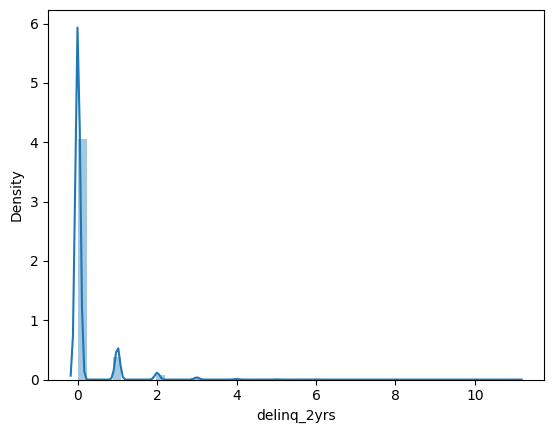

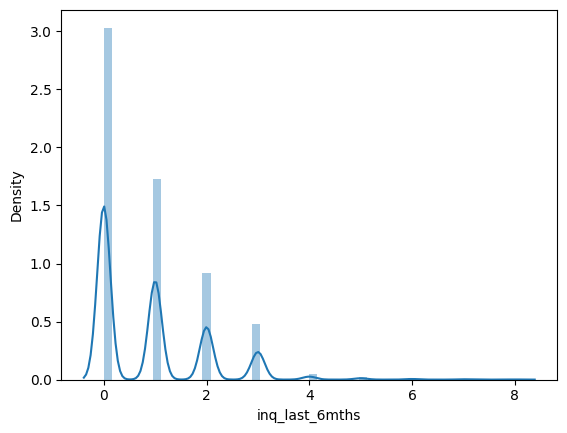

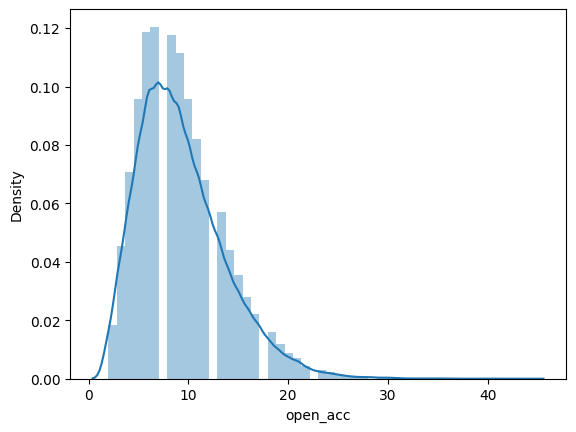

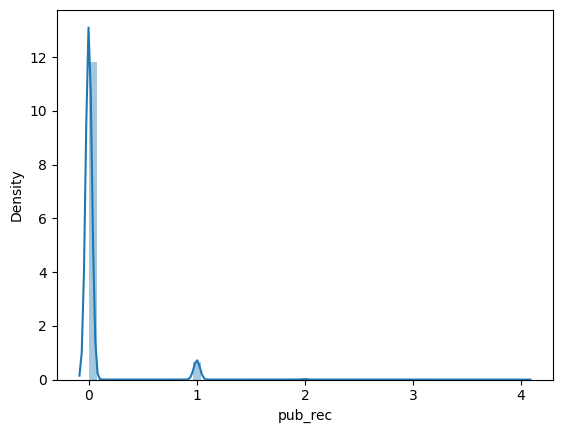

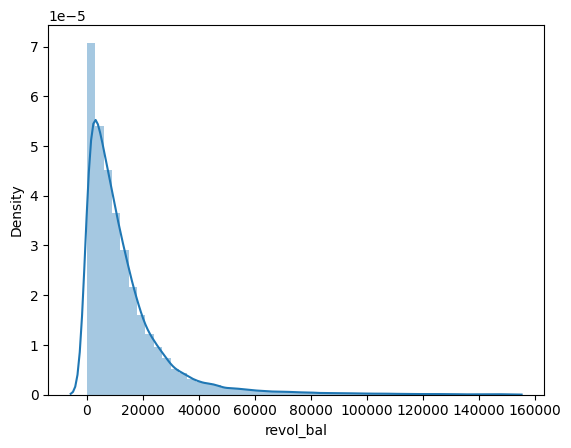

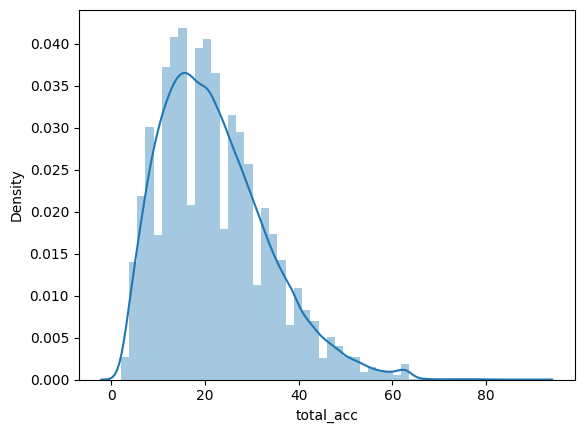

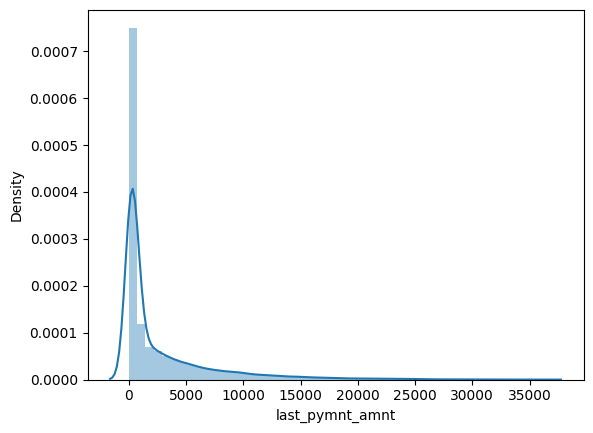

In [ ]:
# Finding the distribution of the data
def distplots(col):
    sns.distplot(df[col])
    plt.show()
for i in list(df_cols.columns)[:]:
    distplots(i)

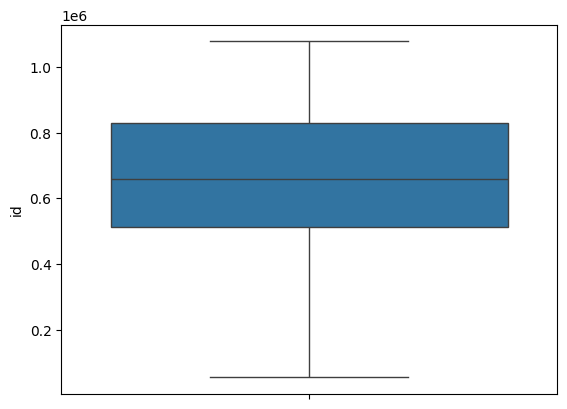

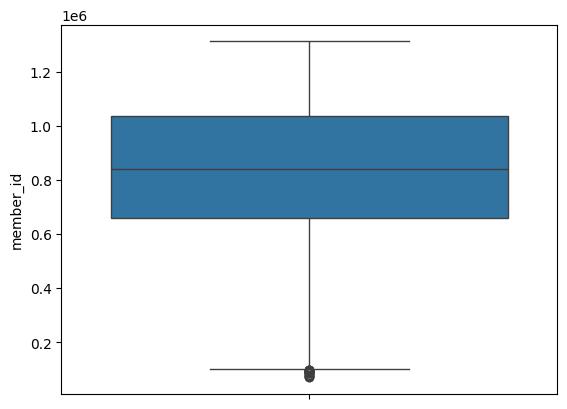

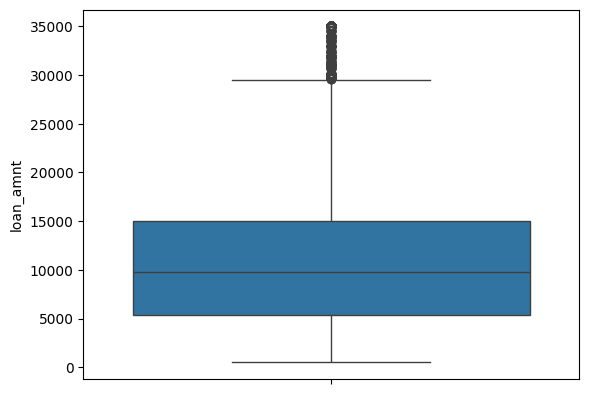

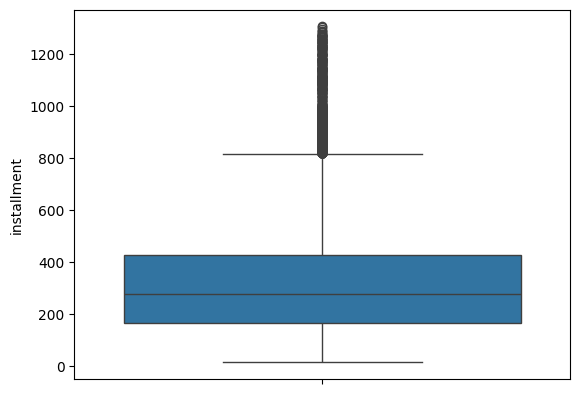

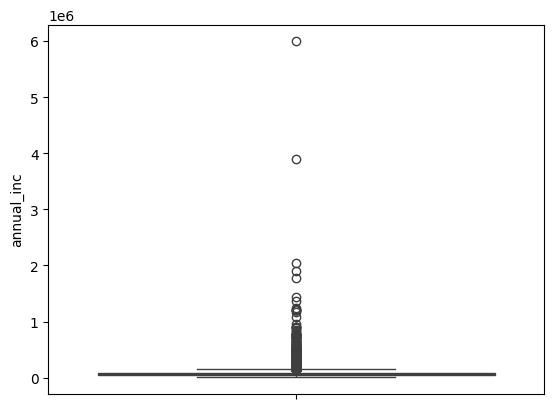

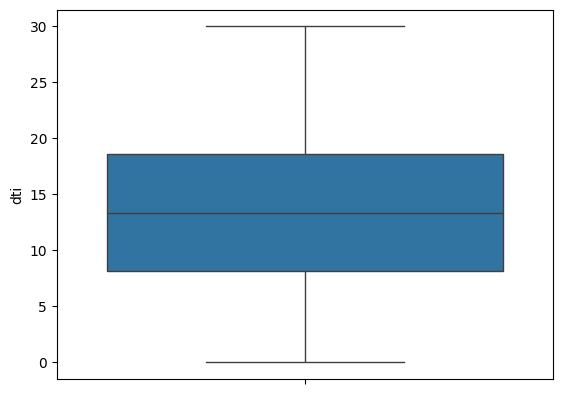

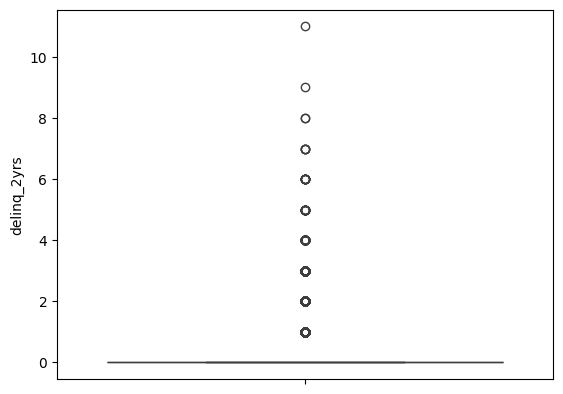

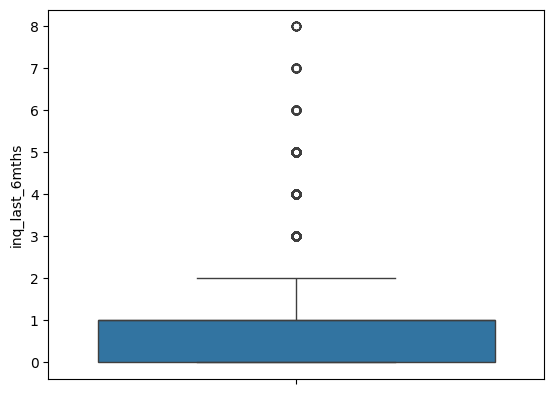

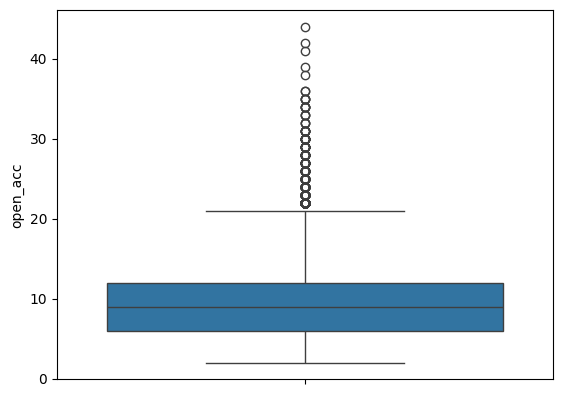

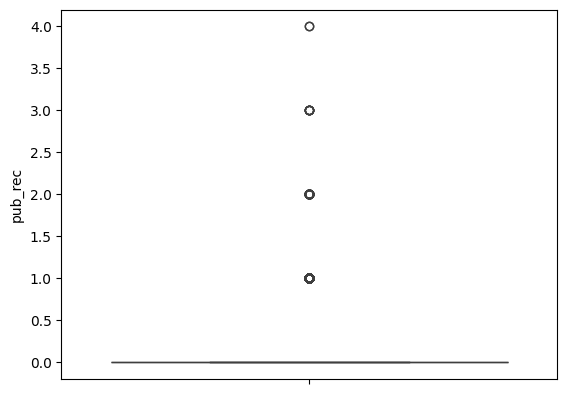

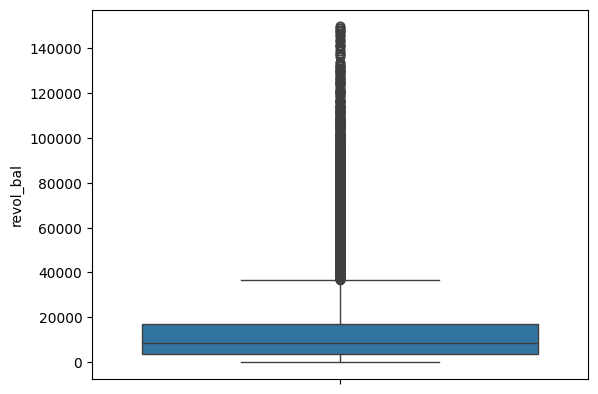

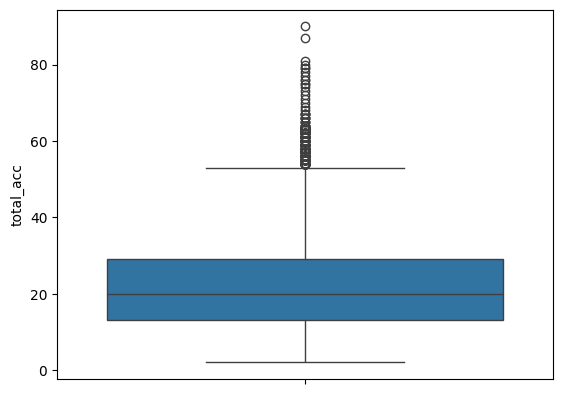

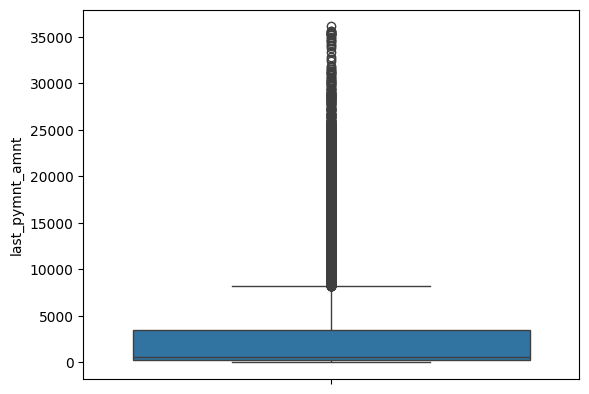

In [ ]:
# Finding the distribution of the data and outliers on the basis of
# boxplots
def boxplots(col):
    sns.boxplot(df_cols[col])
    plt.show()

for i in list(df_cols.columns)[:]:
    boxplots(i)

### Data Cleaning

- Perform missing value treatment
- Remove extra symbols, characters, etc. from appropriate columns

In [ ]:
## Write your code
# For numerical columns, fill with median
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# For categorical columns, fill with mode
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

Dealing with missing values:
- For numerical columns, fill missing values with the median because it's a better choice when there are outliers. Unlike the mean, the median isn't affected by extreme values, so it keeps the data more stable.
- For categorical columns, use the mode to fill missing data. Because it keeps the category distribution as natural as possible without introducing random values.

In [ ]:
## Write your code
# Convert interest rate from string to float
df['int_rate'] = df['int_rate'].str.replace('%', '').astype(float)

# Convert term to numeric (36 or 60 months)
df['term'] = df['term'].str.replace(' months', '').str.strip().astype(int)

# Convert revolving utilization to float
df['revol_util'] = df['revol_util'].str.replace('%', '').astype(float)

Fixing data types:  
- The interest rate ('int_rate') has a '%' symbol, so we remove it and turn it into a number.  
- The loan term ('term') is stored as text like '36 months' or '60 months'. We remove the word 'months' and convert it into an actual number.  
- The revolving utilization ('revol_util') is also written as a percentage.  We remove the '%' and convert it into a number so we can use it in calculations.  

#Checking for outliers

In [ ]:
# q1 = df.describe().T.loc[:,'25%']
# q3 = df.describe().T.loc[:,'75%']
# IQR = q3 - q1
# IQR

# lower_boundary = round(q1 - 1.5*IQR,2)
# upper_boundary = round(q3 + 1.5*IQR,2)

# cols = df.select_dtypes(exclude='object')

# count = 0
# for i in cols:
#     temp = cols[i] > upper_boundary[0]
#     print(f'outliers in {i} are :\n {temp.value_counts()}')
#     print("-----------------------------------------------------")
#     count += 1

In [ ]:
## Write your code
# Handle any outliers
# Using IQR method for numerical columns
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Replace outliers with boundaries
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

In [ ]:
## Write your code
# Check for remaining missing values
print("Remaining missing values after cleaning:")
print(df.isnull().sum().sum())

Remaining missing values after cleaning:
0


##### Dropping the unnecessary columns

- Columns which are not required for analysis - `id`, `member_id`
- Columns which are not available at the time of loan approval (Check the data dictionary and problem statement to understand this more) - `installment` and `last_pymnt_amnt`

In [ ]:
## Drop the above columns
columns_to_drop = ['id', 'member_id']
df = df.drop(columns=columns_to_drop)

# Drop duplicates if any
df = df.drop_duplicates()

# Convert loan_status to binary (0 for default, 1 for fully paid)
df['loan_status_binary'] = np.where(df['loan_status'] == 'Fully Paid', 1, 0)

# Drop the original loan_status column
df = df.drop('loan_status', axis=1)

Dropping data:  
- Droping 'id' and 'member_id' because they are just identifiers and don't help in analysis.  
- Remove any duplicate rows to ensure our data is clean and doesn't have repeated entries.  
- The 'loan_status' column contains text values like 'Fully Paid' and 'Default'. To make it useful, convert it into a binary format:  
- 'Fully Paid' becomes 1 (loan was successfully paid). Everything else becomes 0 (loan was not fully paid, meaning it defaulted).  
- After creating this new binary column, drop the original 'loan_status' column since we don’t need it anymore.  

In [ ]:
## Check the dataframe again
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38770 entries, 0 to 38769
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   loan_amnt            38770 non-null  float64
 1   term                 38770 non-null  int64  
 2   int_rate             38770 non-null  float64
 3   installment          38770 non-null  float64
 4   grade                38770 non-null  object 
 5   sub_grade            38770 non-null  object 
 6   emp_length           38770 non-null  object 
 7   home_ownership       38770 non-null  object 
 8   annual_inc           38770 non-null  float64
 9   verification_status  38770 non-null  object 
 10  purpose              38770 non-null  object 
 11  dti                  38770 non-null  float64
 12  delinq_2yrs          38770 non-null  float64
 13  inq_last_6mths       38770 non-null  float64
 14  open_acc             38770 non-null  float64
 15  pub_rec              38770 non-null 

Perform any additional data preparation steps if needed

In [ ]:
## Write the code
# Perform any additional data preparation steps if needed
print("\nData cleaning completed. Dataset shape after cleaning:", df.shape)


Data cleaning completed. Dataset shape after cleaning: (38770, 21)


In [ ]:
## Write the code

### Exploratory Data Analysis

Let's understand the key drivers of loan default using EDA. This will form the preliminary analysis before we start with our machine learning model building part. We can understand the distributions of different variables, how they are related with loan default and so on.

#### Univariate Analysis

Perform univariate analysis on the following variables. Use visualizations and summary statistics wherever necessary. Document your overall observations as well
- `loan_status`
- `term`
- `grade`
- `purpose`
- `loan_amnt`
- `annual_inc`

*Note* - You can do additional analysis as well

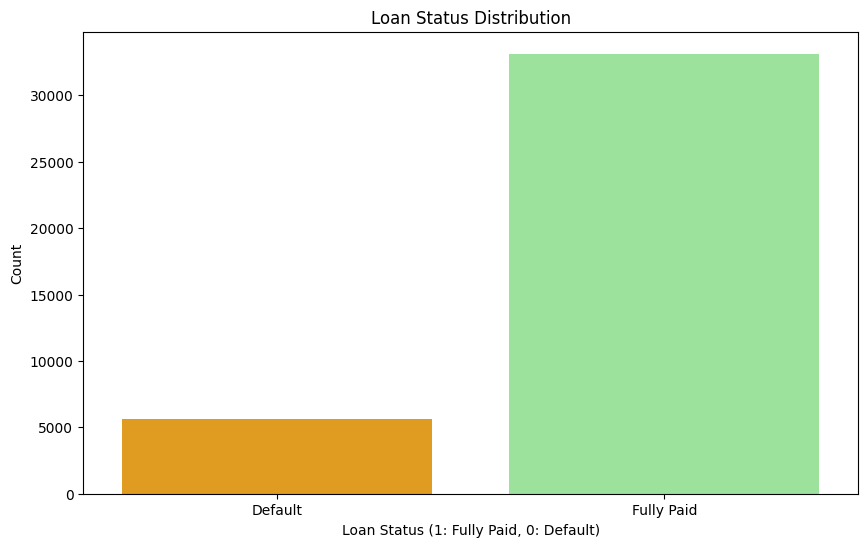

In [ ]:
## Write Code here
# Loan status distribution
plt.figure(figsize=(10, 6))
loan_status_count = df['loan_status_binary'].value_counts()
colors = ['orange', 'lightgreen']  # orange for default, lightgreen for fully paid
sns.barplot(x=loan_status_count.index, y=loan_status_count.values, palette=colors)
plt.title('Loan Status Distribution')
plt.xlabel('Loan Status (1: Fully Paid, 0: Default)')
plt.ylabel('Count')
plt.xticks([0, 1], ['Default', 'Fully Paid'])
plt.show()

Creating a bar chart to see how many loans were fully paid vs. defaulted. This helps us understand the overall loan repayment trends in the dataset. By observing above chart its clear that fully paid count is more.

In [ ]:
## Write Code here
# Check class imbalance
# Checking if the dataset has an imbalance between fully paid and defaulted loans. This helps us understand if one category dominates the other, which can impact model performance.
print("\nLoan status distribution:")
print(df['loan_status_binary'].value_counts(normalize=True) * 100)


Loan status distribution:
loan_status_binary
1    85.468145
0    14.531855
Name: proportion, dtype: float64


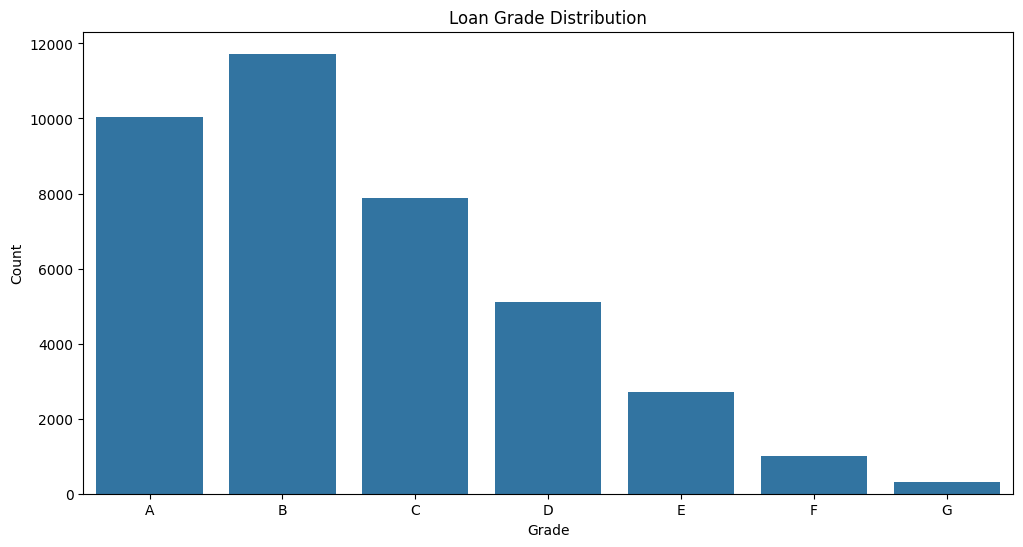

In [ ]:
## Write Code here
# Grade distribution
plt.figure(figsize=(12, 6))
grade_count = df['grade'].value_counts().sort_index()
sns.barplot(x=grade_count.index, y=grade_count.values)
plt.title('Loan Grade Distribution')
plt.xlabel('Grade')
plt.ylabel('Count')
plt.show()

Creating a bar chart to show how loans are distributed across different grades. This helps us understand the creditworthiness of borrowers in the dataset.  By observing above chart one can easily identify that B grade is higher and G is low count.

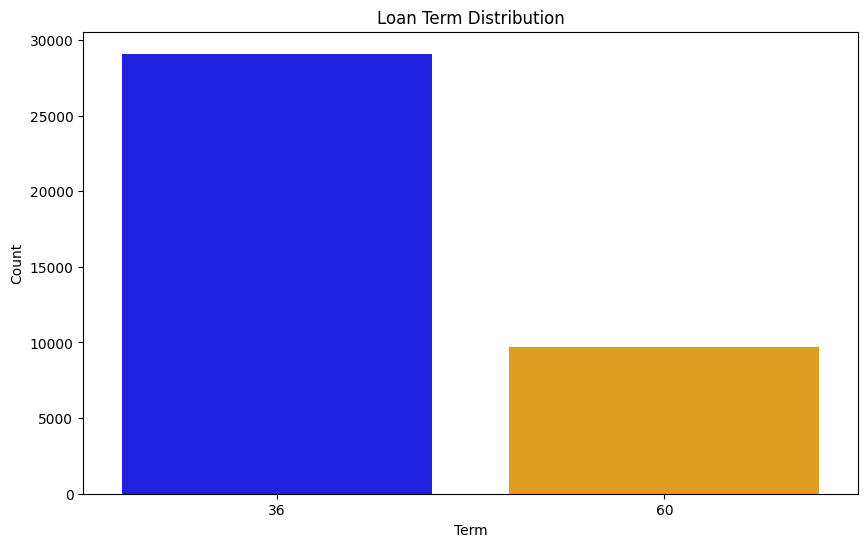

In [ ]:
# Term distribution
plt.figure(figsize=(10, 6))
term_count = df['term'].value_counts()
colors = ['blue', 'orange']
sns.barplot(x=term_count.index, y=term_count.values, palette=colors)
plt.title('Loan Term Distribution')
plt.xlabel('Term')
plt.ylabel('Count')
plt.show()

Using bar chart the distribution of loan terms (length of the loan). This helps us see how many loans are for shorter terms vs. longer terms. Here the 36 months is more than 60 months.

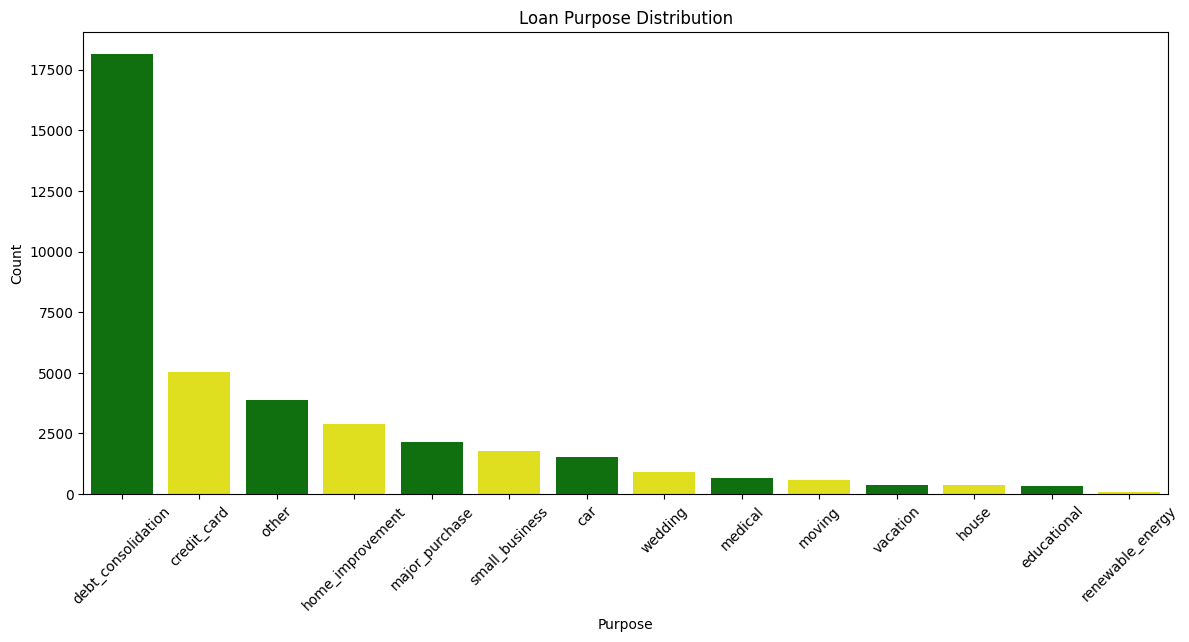

In [ ]:
# Purpose distribution
plt.figure(figsize=(14, 6))
purpose_count = df['purpose'].value_counts()
colors = ['green', 'yellow']
sns.barplot(x=purpose_count.index, y=purpose_count.values, palette=colors)
plt.title('Loan Purpose Distribution')
plt.xlabel('Purpose')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

Creating a bar chart to show why people are taking loans. This helps us see the most common reasons people borrow money. Here we can see that debt_consolidation is highest purpose and renewable_energy is lowest one

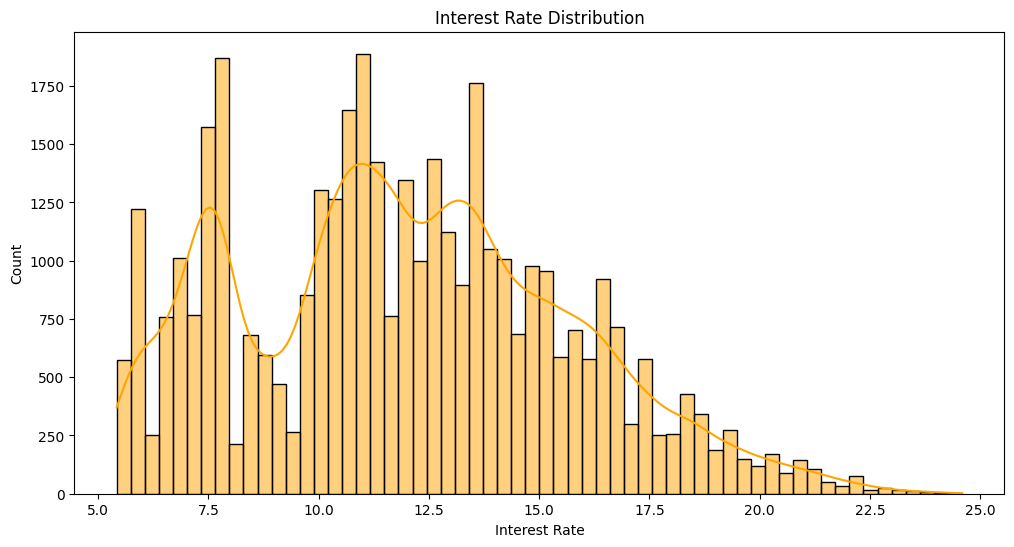

In [ ]:
## Write Code here
# Interest rate distribution
plt.figure(figsize=(12, 6))
sns.histplot(df['int_rate'], kde=True, color='orange')
plt.title('Interest Rate Distribution')
plt.xlabel('Interest Rate')
plt.show()

Plotting a histogram to see how interest rates are distributed. This helps us understand the range of interest rates and how frequently they occur.  

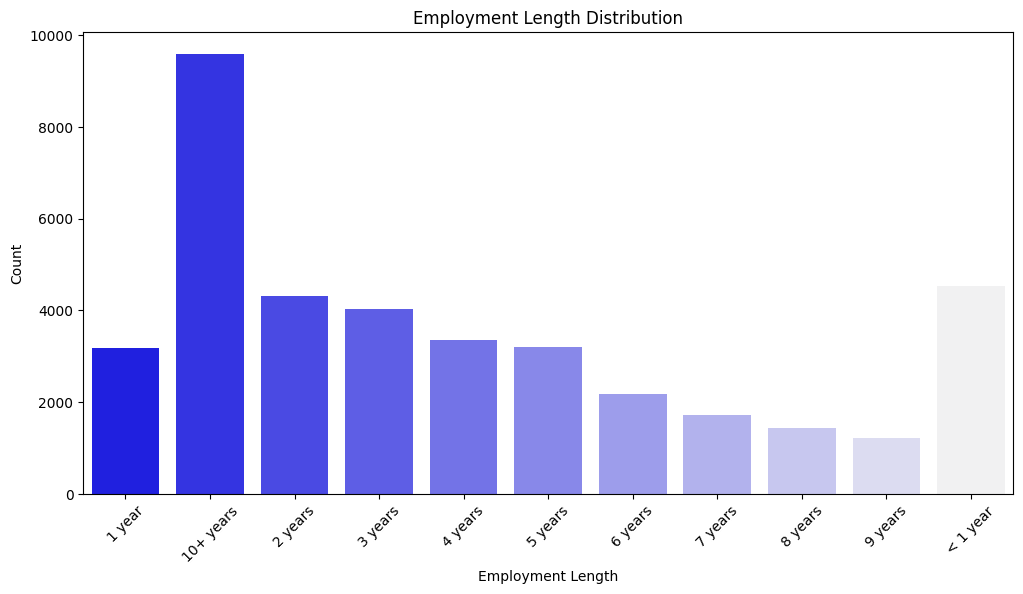

In [ ]:
## Write Code here
# Employment length distribution
plt.figure(figsize=(12, 6))
emp_length_count = df['emp_length'].value_counts().sort_index()
colors = sns.light_palette("blue", as_cmap=False, n_colors=len(emp_length_count))[::-1]
sns.barplot(x=emp_length_count.index, y=emp_length_count.values, palette=colors)
plt.title('Employment Length Distribution')
plt.xlabel('Employment Length')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

Creating a bar chart to show the work experience of borrowers. This helps us see the most common employment lengths among loan applicants. By observing 10+ years is more and lowest is 9 years.

**Observations**

- Document your observations here

  •	The dataset shows an imbalance in the loan status, with more fully paid loans compared to defaults.
	•	B and C grade loans are the most common, meaning many borrowers fall into these credit categories.
	•	When it comes to loan terms, 36-month loans are far more popular than 60-month ones.
	•	Debt consolidation is the primary reason people apply for loans.
	•	Interest rates are not evenly distributed, with most loans having lower rates but a few reaching much higher percentages.
	•	A large number of borrowers have over a decade of work experience, indicating that many applicants have stable employment histories.

#### Bivariate Analysis

For the bivariate analysis, you can perform multiple analysis such as follows:

- How the default rate varies across the different variables
- Correlation Matrix
- etc.

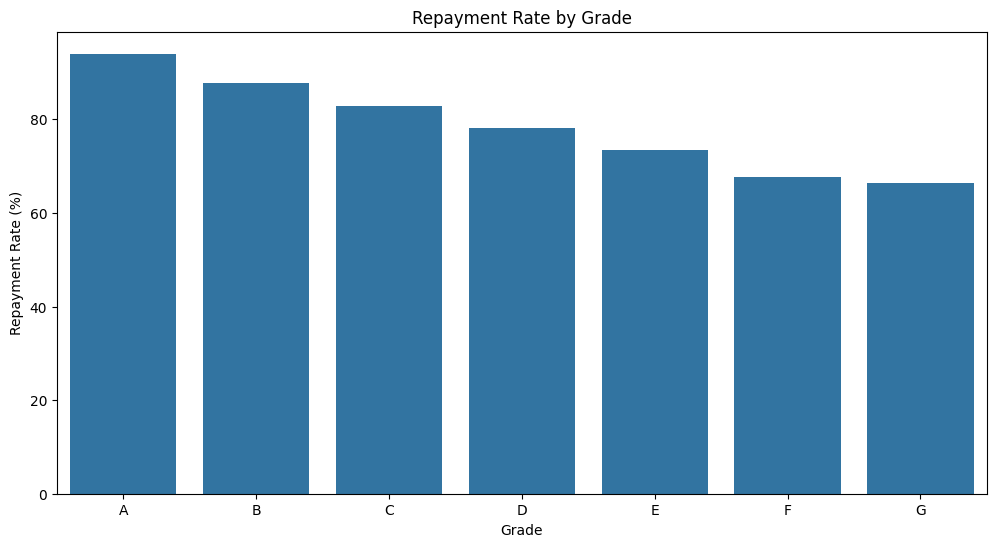

In [ ]:
#Write your code here
# Default rate by grade
plt.figure(figsize=(12, 6))
default_by_grade = df.groupby('grade')['loan_status_binary'].mean() * 100
sns.barplot(x=default_by_grade.index, y=default_by_grade.values)
plt.title('Repayment Rate by Grade')
plt.xlabel('Grade')
plt.ylabel('Repayment Rate (%)')
plt.show()

Checking how loan repayment rates vary by grade. This helps us see which grades are more likely to have successful repayments.Here grade A paymenent rate is high than grade G

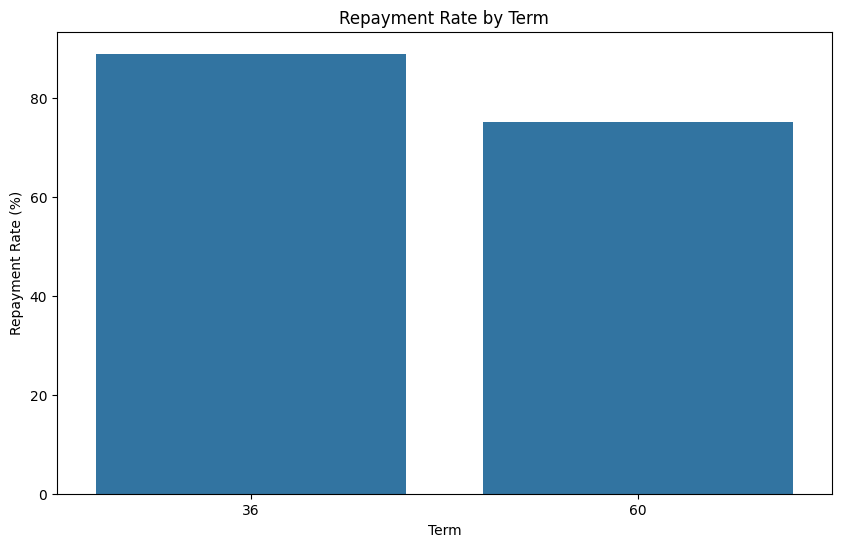

In [ ]:
#Write your code here
# Default rate by term
plt.figure(figsize=(10, 6))
default_by_term = df.groupby('term')['loan_status_binary'].mean() * 100
sns.barplot(x=default_by_term.index, y=default_by_term.values)
plt.title('Repayment Rate by Term')
plt.xlabel('Term')
plt.ylabel('Repayment Rate (%)')
plt.show()

Checking the repayment rates for different loan terms. This helps us understand whether shorter or longer loans are more likely to be repaid.  By observing above chart 36months repayment rate is higher than 60 months

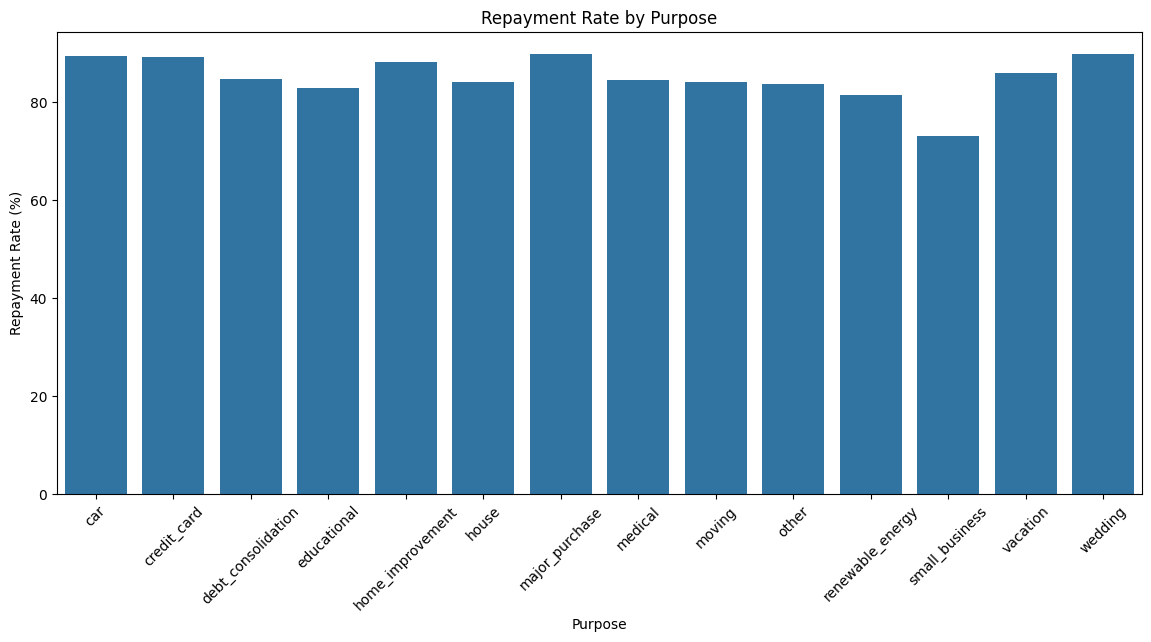

In [ ]:
#Write your code here
# Default rate by purpose
plt.figure(figsize=(14, 6))
default_by_purpose = df.groupby('purpose')['loan_status_binary'].mean() * 100
sns.barplot(x=default_by_purpose.index, y=default_by_purpose.values)
plt.title('Repayment Rate by Purpose')
plt.xlabel('Purpose')
plt.ylabel('Repayment Rate (%)')
plt.xticks(rotation=45)
plt.show()

Creating repayment rates based on the purpose of the loan. This helps us understand which loan purposes have higher or lower repayment success.  Based on above chart, major_purchase and wedding purposes are highest and small_business is lowest.

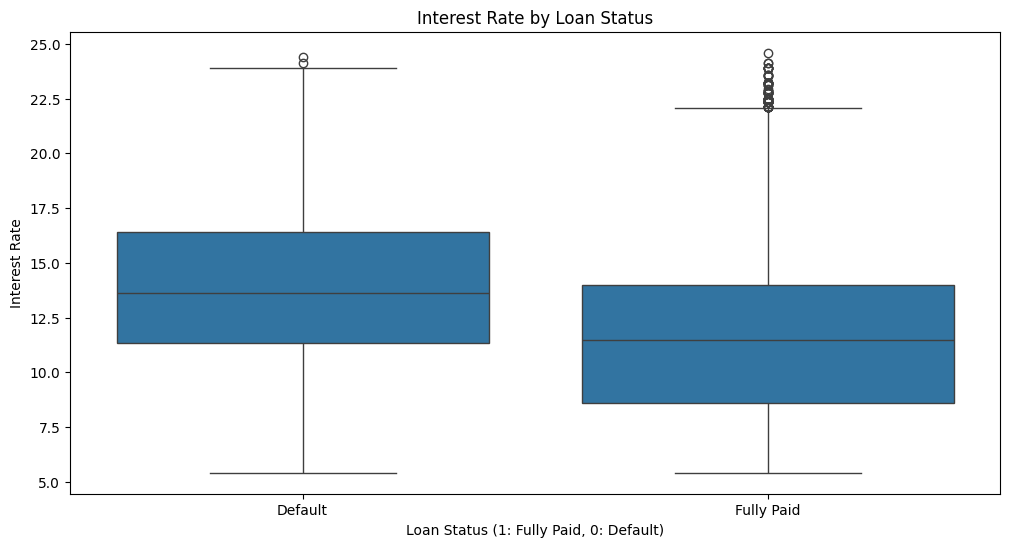

In [ ]:
#Write your code here
# Interest rate vs loan status
plt.figure(figsize=(12, 6))
sns.boxplot(x='loan_status_binary', y='int_rate', data=df)
plt.title('Interest Rate by Loan Status')
plt.xlabel('Loan Status (1: Fully Paid, 0: Default)')
plt.ylabel('Interest Rate')
plt.xticks([0, 1], ['Default', 'Fully Paid'])
plt.show()

Chart for interest rates for fully paid vs. defaulted loans. This helps us see if higher interest rates are linked to a higher chance of default.  Here defaults are higher than fully paid.

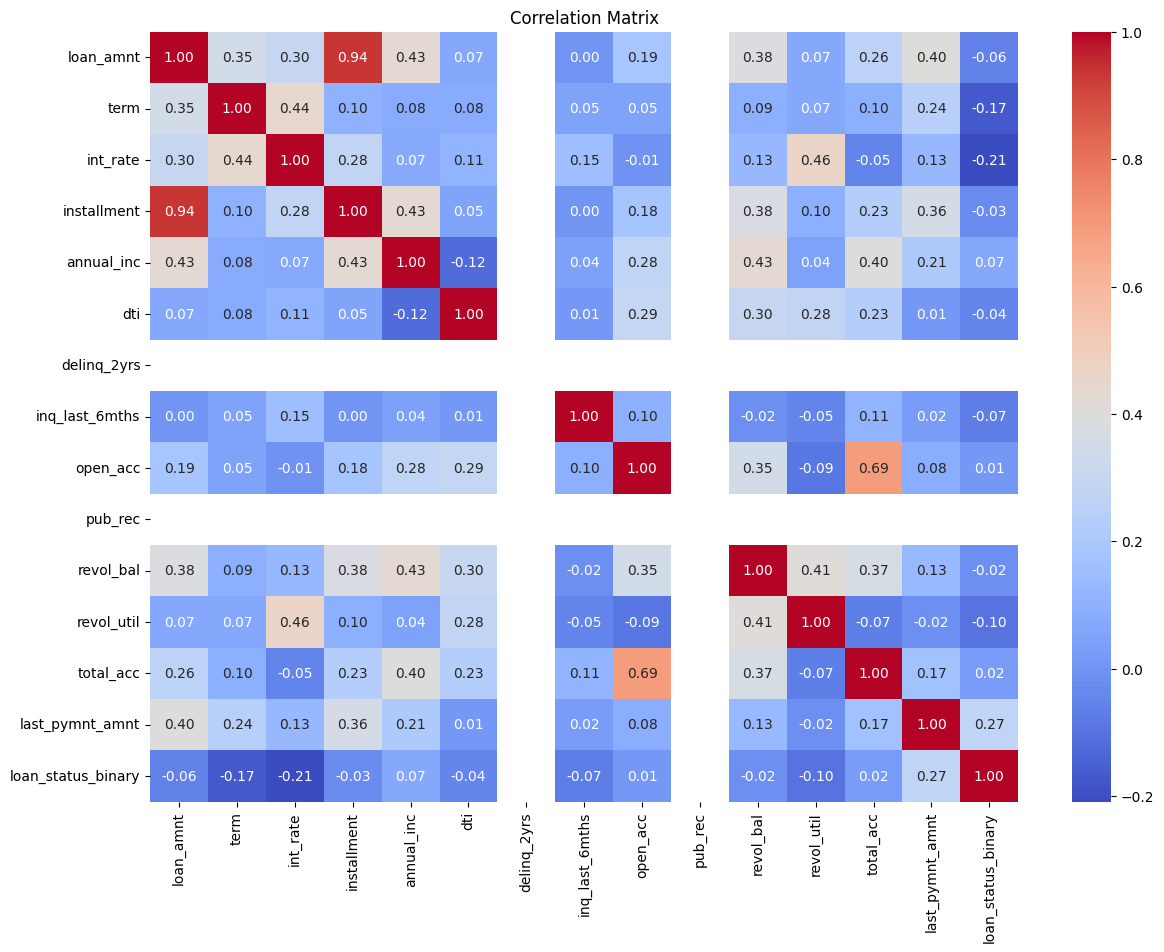

In [ ]:
#Write your code here
# Correlation matrix for numerical features
plt.figure(figsize=(14, 10))
corr_matrix = df.select_dtypes(include=['float64', 'int64']).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

Exploring relationships between numerical features using a heatmap. This helps us see which features are strongly related to each other.  
The heatmap shows that bigger loans come with higher monthly payments, and loans with higher interest rates are more likely to default. People with higher incomes tend to borrow more. Credit usage doesn’t have a big impact on repayment. Larger loans seem slightly riskier, they may default more often.

Bivariate analysis-Observations:
	•	Loan grade impacts repayment rates—borrowers with A-grade loans have the highest repayment success, while those in G-grade loans struggle the most.
	•	Shorter-term loans (36 months) tend to be repaid more often compared to longer-term (60-month) loans.
	•	Small business loans are riskier, showing lower repayment rates than loans taken for other purposes.
	•	Higher interest rates often lead to more defaults, suggesting that riskier borrowers are charged more but struggle to repay.
	•	Several numerical features in the dataset show moderate correlations with loan repayment, meaning certain factors can help predict whether a loan will be fully paid or not.

#### Pre-ML Data Pre-Processing

Before building the machine learning model, we shall perform
- encoding on all the categorical variables
- handle class imbalance
- train-test split
- scaling

##### Encoding variables

In [ ]:
# Write code here
!pip install -U scikit-learn
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Define features (X) and target variable (y)
X = df.drop('loan_status_binary', axis=1)
y = df['loan_status_binary']

# Assuming 'df' is your DataFrame
numerical_cols = X.select_dtypes(include=['number']).columns

# Preparing the data. 'X' contains all the features except the loan status, which is our target 'y'. We need to preprocess numerical columns by handling missing values and scaling them. This will ensures the data is clean and ready for modeling.  

In [ ]:
# Splitting our dataset between training and testing set
from sklearn.model_selection import train_test_split
# X_train, X_test, y_train, y_test = ## Write code here
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("\nTrain-test split completed:")
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train class distribution: {pd.Series(y_train).value_counts()}")
print(f"y_test class distribution: {pd.Series(y_test).value_counts()}")

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()
numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()


Train-test split completed:
X_train shape: (31016, 20)
X_test shape: (7754, 20)
y_train class distribution: loan_status_binary
1    26509
0     4507
Name: count, dtype: int64
y_test class distribution: loan_status_binary
1    6627
0    1127
Name: count, dtype: int64


Dividing the dataset into training and testing sets. The model will learn from the training data and be evaluated on the test data. Stratification ensures the target variable is balanced in both sets. Also separate categorical and numerical columns for proper preprocessing.  

In [ ]:
# Write code here
# Create preprocessor for pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', MinMaxScaler())
        ]), numerical_cols),
        ('cat', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore'))
        ]), categorical_cols)
    ])

# Create the preprocessing pipeline
preprocessing_pipeline = Pipeline([
    ('preprocessor', preprocessor)
])

Creating a preprocessing pipeline to prepare the data for modeling.  
Numerical columns: Missing values are filled with the median, and values are scaled for consistency.  
Categorical columns: Missing values are replaced with the most common value, and categories are one-hot encoded.
This makes the dataset cleaner and more suitable.  

In [ ]:
# Write code here
# Apply preprocessing
X_train_processed = preprocessing_pipeline.fit_transform(X_train)
X_test_processed = preprocessing_pipeline.transform(X_test)

print(f"X_train shape after preprocessing: {X_train_processed.shape}")
print(f"X_test shape after preprocessing: {X_test_processed.shape}")

X_train shape after preprocessing: (31016, 83)
X_test shape after preprocessing: (7754, 83)


Applying the preprocessing steps to transform the training and testing data.  
The training data is fitted and transformed, while the test data is only transformed. This ensures that numerical values are scaled, missing values are handled, and categorical data is encoded.  
  

**Handling Class Imbalance**

Suggestion - Perform SMOTE here

In [ ]:
from imblearn.over_sampling import SMOTE

In [ ]:
## Write code
# To handle class imbalance using SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)

In [ ]:
## Write code

In [ ]:
## Check the distribution of class in the newly resampled data
print("\nClass distribution after SMOTE:")
print(pd.Series(y_train_resampled).value_counts(normalize=True) * 100)

print(f"Training set size after SMOTE: {X_train_resampled.shape}")

print("\nData preprocessing completed and ready for model building.")


Class distribution after SMOTE:
loan_status_binary
0    50.0
1    50.0
Name: proportion, dtype: float64
Training set size after SMOTE: (53018, 83)

Data preprocessing completed and ready for model building.


Checking the class distribution after applying SMOTE to balance the dataset.  
To ensures that both classes have equal representation, preventing bias in the model i.e loan_status_binary 0-50.0 and 1-50.0. Printing the new training set size after resampling(53018,83).  

**Train-test split**

Now that we have handled class imbalance, let's perform the train-test split. We have to do a few additional imports

In [ ]:
## Check the samples


**Scaling**

In [ ]:
from sklearn.preprocessing import MinMaxScaler
# Write code for MinMax Scaler
print("\nApplying scaling to numerical features...")
# MinMaxScaler scales features to a given range, usually [0, 1] by default
# Formula: X_scaled = (X - X_min) / (X_max - X_min)

# Implementing MinMaxScaler for demonstration
from sklearn.preprocessing import MinMaxScaler

# Note: This code demonstrates how MinMaxScaler works, but the actual scaling
# is already performed in the preprocessing pipeline above
def demonstrate_min_max_scaling(sample_data):
    # Create a MinMaxScaler instance
    min_max_scaler = MinMaxScaler()

    # Fit and transform the data
    scaled_data = min_max_scaler.fit_transform(sample_data.reshape(-1, 1))

    print("Original data sample:", sample_data)
    print("Scaled data sample:", scaled_data.flatten())
    print("Min value in original data:", np.min(sample_data))
    print("Max value in original data:", np.max(sample_data))
    print("Min value in scaled data:", np.min(scaled_data))
    print("Max value in scaled data:", np.max(scaled_data))

    return scaled_data

# Demonstrate with a small sample from a numerical column
if len(X_train) > 0 and 'int_rate' in X_train.columns:
    sample_data = X_train['int_rate'].values[:5]
    demonstrate_min_max_scaling(sample_data)

print("MinMaxScaler is applied to all numerical features in the preprocessing pipeline.")


Applying scaling to numerical features...
Original data sample: [15.23 11.48  7.88 16.29 18.25]
Scaled data sample: [0.70877531 0.34715526 0.         0.81099325 1.        ]
Min value in original data: 7.88
Max value in original data: 18.25
Min value in scaled data: 0.0
Max value in scaled data: 0.9999999999999999
MinMaxScaler is applied to all numerical features in the preprocessing pipeline.


Showing how MinMaxScaler works by scaling a small sample of numerical data.  
MinMaxScaler transforms values to a fixed range 0 to 1 for consistency.  
It normalizes data using the formula: (X - min) / (max - min).  
This ensures all numerical features have a similar scale, improving model accuracy. While scaling is already done in the preprocessing pipeline, this example helps understand its effect.  

### Model Building and Model Evaluation

- Your task is to build at least 3 models and evaluate their performance
- Start with a baseline model such as logistic regression
- Build additional models like decision trees, random forests, XGboost, etc.
- Make sure you're checking for overfitting and underfitting
- Use cross-validation and hyperparamater tuning to fit the best models
- Evaluate each of the model using metrics such as accuracy, precision, recall, ROC-AUC score, etc.
- Select the best possible model that you will be using for classfication

Let's start off with the simplest model - Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


Logistic Regression Model Evaluation:
Accuracy: 0.7389734330668042
Precision: 0.9565562388414997
Recall: 0.727629394899653
F1 Score: 0.8265341103873843
ROC-AUC Score: 0.8608539800276597


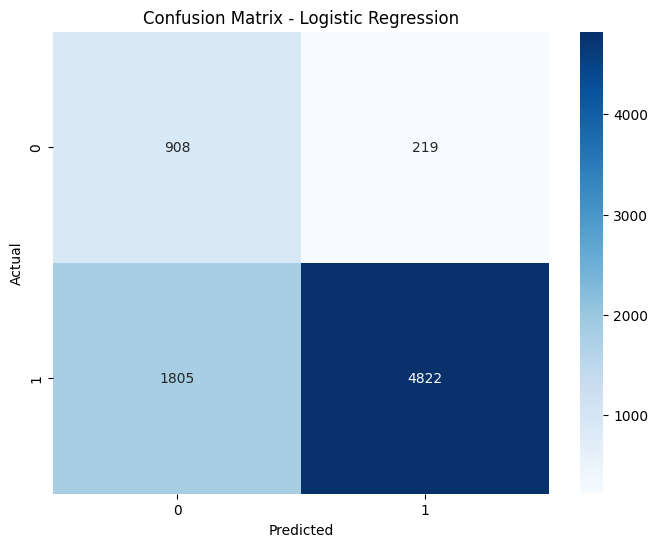

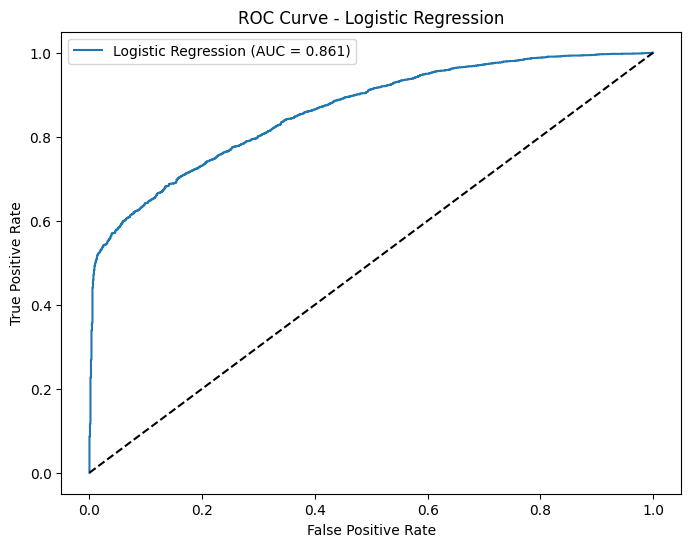

In [ ]:
## Build the model
## Check its evaluation metrics

# Logistic Regression
# Build the model
lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_resampled, y_train_resampled)

# Make predictions
y_pred_lr = lr_model.predict(X_test_processed)
y_pred_proba_lr = lr_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("\nLogistic Regression Model Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba_lr))

# Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
plt.figure(figsize=(8, 6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_pred_proba_lr):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.show()

The Logistic Regression model performs fairly well in predicting loan repayment. With an accuracy of 73.9%, the model correctly classifies most loans. The precision of 95.7% means that when the model predicts a loan will be fully paid, it is correct most of the time. However, the recall of 72.8% indicates that it misses some defaulted loans. The F1-score of 82.7% shows a good balance between precision and recall. The ROC-AUC score of 86.1% suggests that the model does a solid job distinguishing between fully paid and defaulted loans. While the performance is good, improving recall could help catch more default cases.


Random Forest Model Evaluation:
Accuracy: 0.8643280887283983
Precision: 0.9054545454545454
Recall: 0.9393390674513354
F1 Score: 0.9220856169456377
ROC-AUC Score: 0.8645874631073522


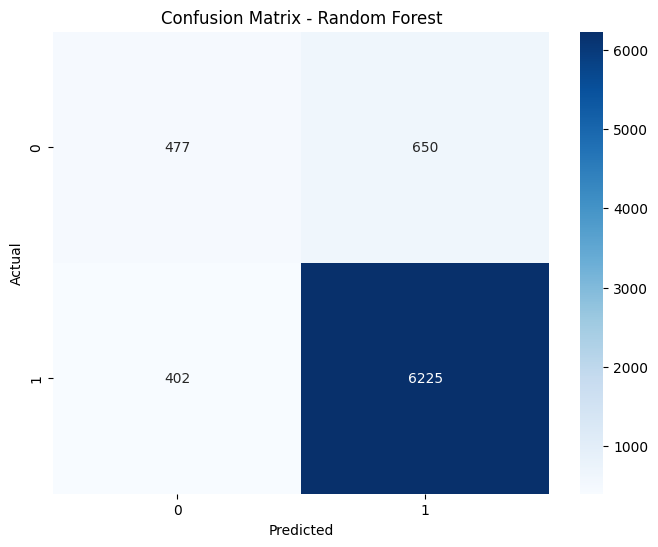

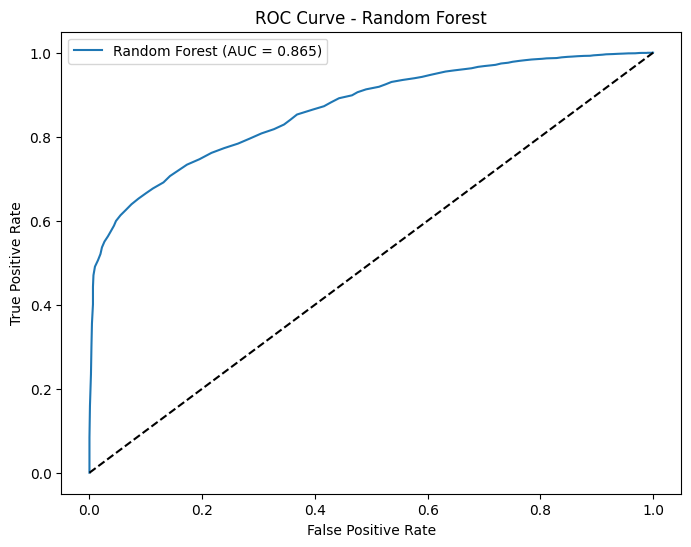

<Figure size 1200x800 with 0 Axes>

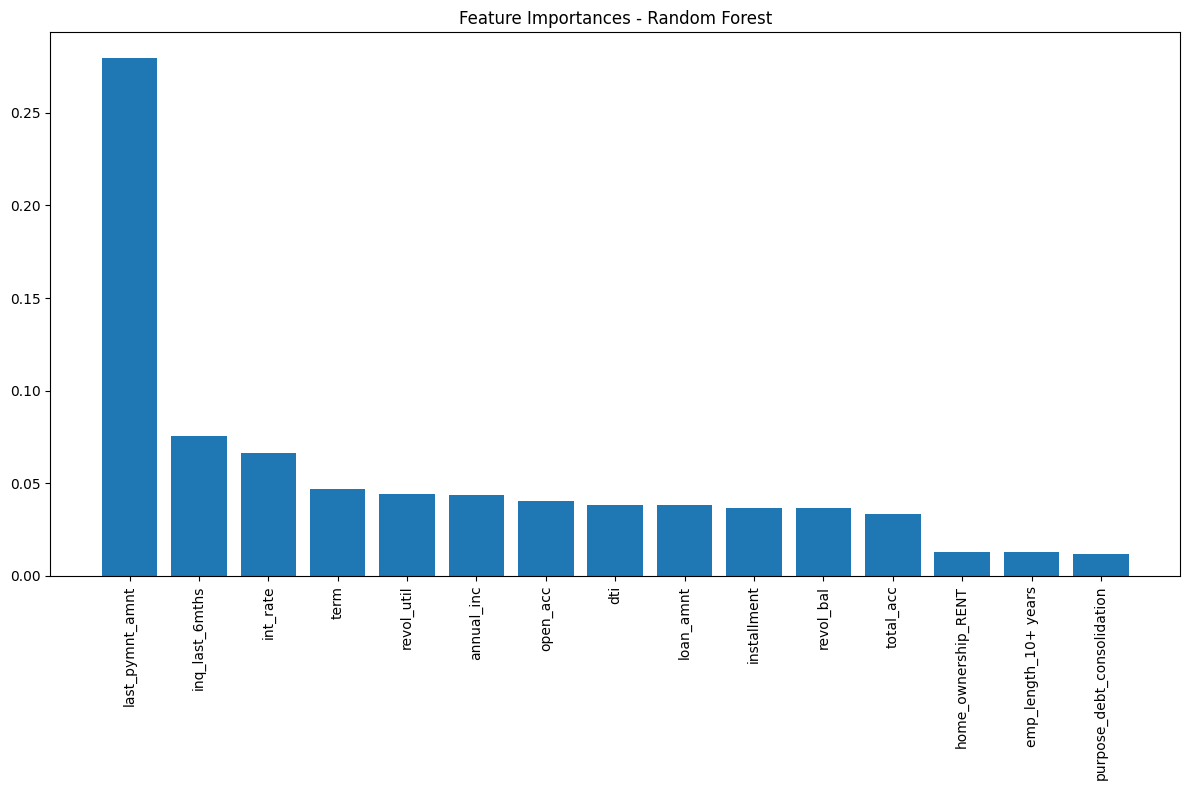

In [ ]:
# Random Forest model
from sklearn.ensemble import RandomForestClassifier

# Build the model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train_resampled, y_train_resampled)

# Make predictions
y_pred_rf = rf_model.predict(X_test_processed)
y_pred_proba_rf = rf_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("\nRandom Forest Model Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba_rf))

# Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_pred_proba_rf)
plt.figure(figsize=(8, 6))
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_pred_proba_rf):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Random Forest')
plt.legend()
plt.show()

# Feature importance
feature_names = (
    numerical_cols +
    list(preprocessing_pipeline.named_steps['preprocessor']
         .transformers_[1][1]
         .named_steps['onehot']
         .get_feature_names_out(categorical_cols))
)

plt.figure(figsize=(12, 8))
# Sort features by importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
top_indices = indices[:15]  # Top 15 features

# Plot feature importances
plt.figure(figsize=(12, 8))
plt.title('Feature Importances - Random Forest')
plt.bar(range(len(top_indices)), importances[top_indices], align='center')
plt.xticks(range(len(top_indices)), [feature_names[i] for i in top_indices], rotation=90)
plt.tight_layout()
plt.show()

The Random Forest model performs significantly better than Logistic Regression, achieving a high accuracy of 86.4%. It correctly predicts most loans with a precision of 90.5%, meaning when it predicts a loan will be fully paid, it is correct most of the time. The recall of 93.9% indicates that it successfully identifies most defaulted loans, making it a strong model for risk assessment. The F1-score of 92.2% shows a great balance between precision and recall. Additionally, the ROC-AUC score of 86.5% suggests that the model effectively distinguishes between fully paid and defaulted loans.


Gradient Boosting Model Evaluation:
Accuracy: 0.8603301521795202
Precision: 0.9216610891390326
Recall: 0.9142900256526332
F1 Score: 0.9179607605484433
ROC-AUC Score: 0.881257992598106


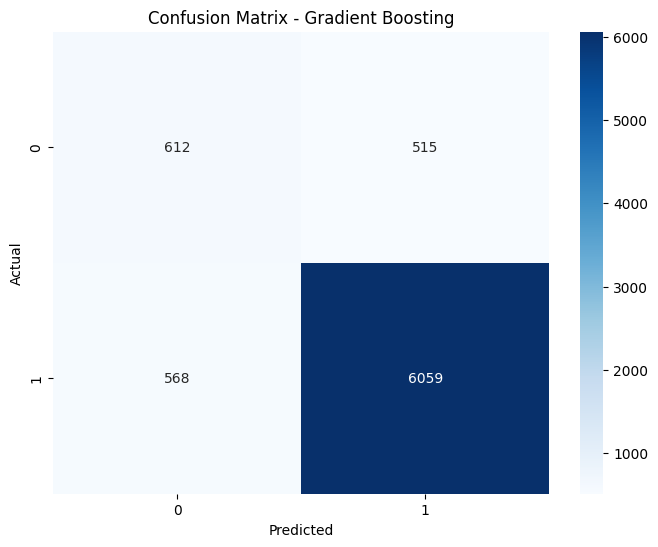

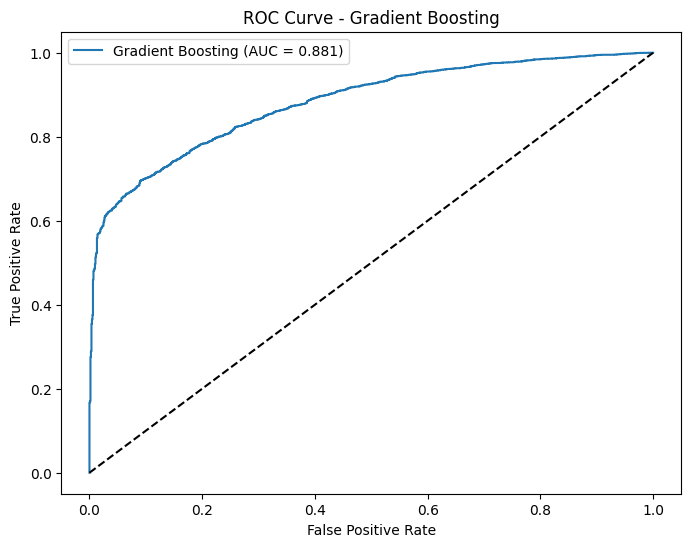

In [ ]:
# Gradient Boosting model
from sklearn.ensemble import GradientBoostingClassifier

# Build the model
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train_resampled, y_train_resampled)

# Make predictions
y_pred_gb = gb_model.predict(X_test_processed)
y_pred_proba_gb = gb_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("\nGradient Boosting Model Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba_gb))

# Confusion Matrix
cm_gb = confusion_matrix(y_test, y_pred_gb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Gradient Boosting')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve for Gradient Boosting
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_pred_proba_gb)
plt.figure(figsize=(8, 6))
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {roc_auc_score(y_test, y_pred_proba_gb):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Gradient Boosting')
plt.legend()
plt.show()

The Gradient Boosting model delivers strong performance with an accuracy of 86.0%, showing that it correctly predicts most loan repayments. It has a precision of 92.2%, meaning when it predicts a loan will be fully paid, it’s usually right. The recall of 91.4% indicates that it effectively identifies most defaulted loans. The F1-score of 91.8% shows a solid balance between precision and recall. Additionally, the ROC-AUC score of 88.1% suggests that the model does an excellent job distinguishing between fully paid and defaulted loans.


Decision Tree Model Evaluation:
Accuracy: 0.8149342274954862
Precision: 0.9039838157485216
Recall: 0.8765655651124189
F1 Score: 0.8900635869148855
ROC-AUC Score: 0.6645472013672121


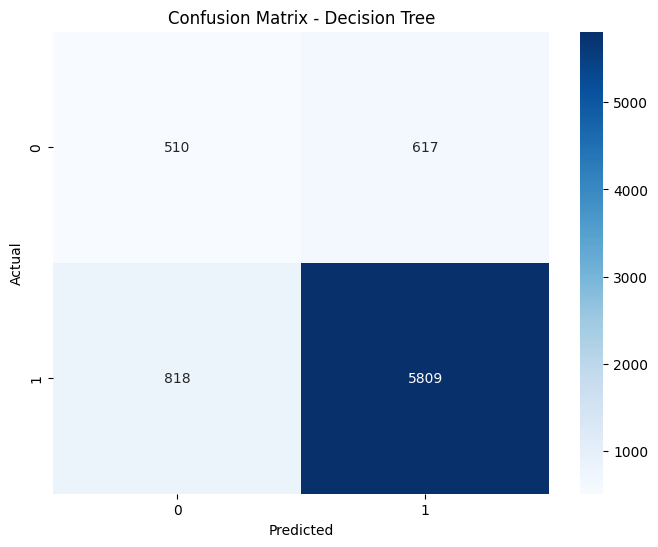

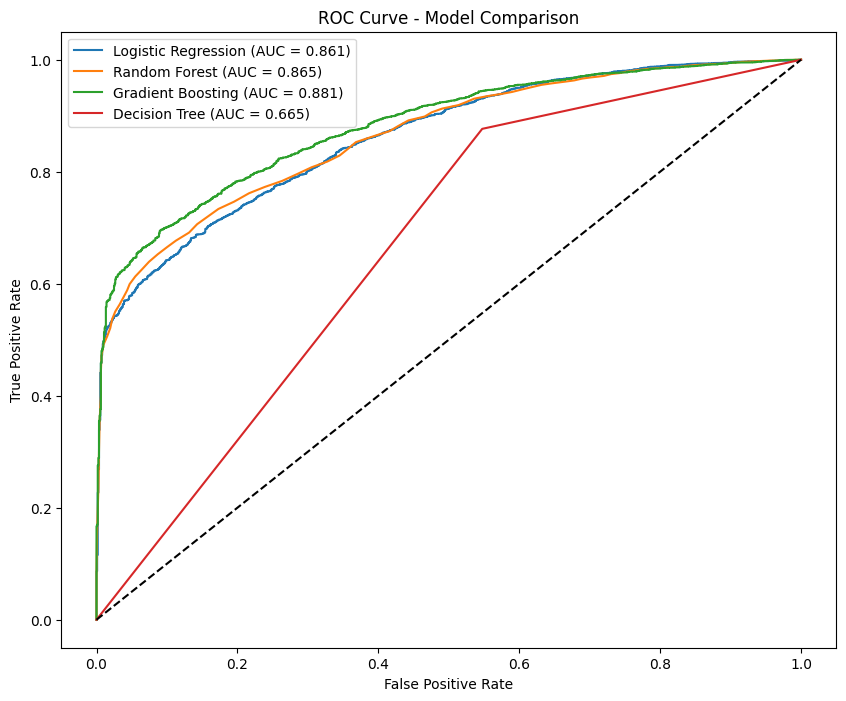

In [ ]:
# Decision Tree model
from sklearn.tree import DecisionTreeClassifier

# Build the model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_resampled, y_train_resampled)

# Make predictions
y_pred_dt = dt_model.predict(X_test_processed)
y_pred_proba_dt = dt_model.predict_proba(X_test_processed)[:, 1]

# Evaluate the model
print("\nDecision Tree Model Evaluation:")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC Score:", roc_auc_score(y_test, y_pred_proba_dt))

# Confusion Matrix for Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# ROC Curve - Compare all models
plt.figure(figsize=(10, 8))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_pred_proba_lr):.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_pred_proba_rf):.3f})')
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_pred_proba_gb)
plt.plot(fpr_gb, tpr_gb, label=f'Gradient Boosting (AUC = {roc_auc_score(y_test, y_pred_proba_gb):.3f})')
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_pred_proba_dt)
plt.plot(fpr_dt, tpr_dt, label=f'Decision Tree (AUC = {roc_auc_score(y_test, y_pred_proba_dt):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Model Comparison')
plt.legend()
plt.show()

The Decision Tree model performs reasonably well, achieving an accuracy of 81.5%, meaning it correctly predicts most loan repayments. It has a precision of 90.4%, indicating that when it predicts a loan will be fully paid, it’s right most of the time. The recall of 87.7% suggests that it does a decent job identifying defaulted loans, but it is not as strong as Random Forest or Gradient Boosting. The F1-score of 89.0% shows a good balance between precision and recall. However, the ROC-AUC score of 66.5% is quite low, the model struggles to separate fully paid and defaulted loans effectively.

<Figure size 800x600 with 0 Axes>

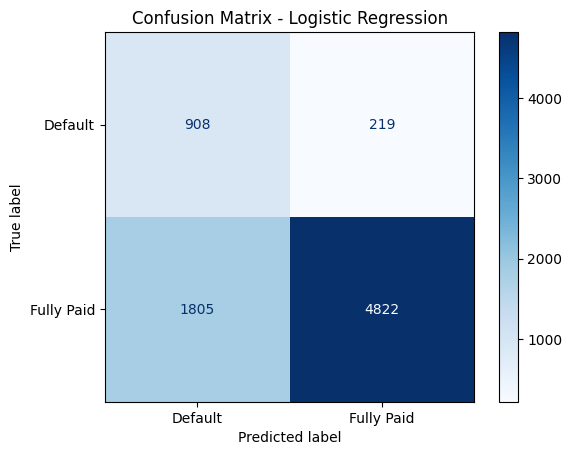

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## Plot the Confusion Matrix
#Logistic Regression- Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(8, 6))
# Using ConfusionMatrixDisplay as specified in starter code
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=['Default', 'Fully Paid'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

<Figure size 800x600 with 0 Axes>

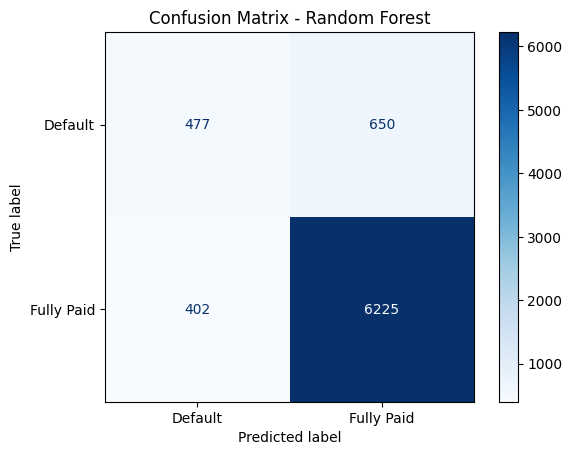

In [ ]:
# Random Forest- Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
# Using ConfusionMatrixDisplay as specified in starter code
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Default', 'Fully Paid'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

<Figure size 800x600 with 0 Axes>

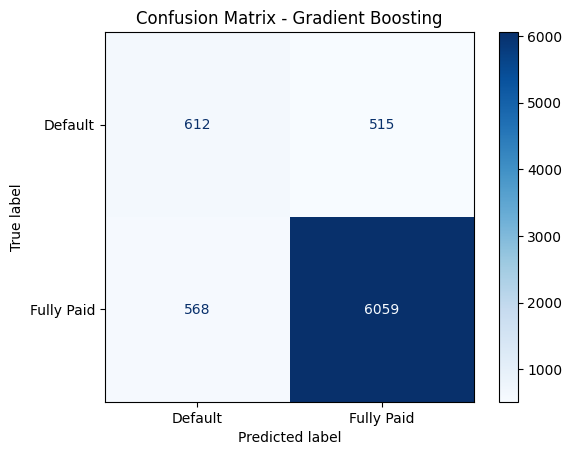

In [ ]:
# Gradient Boosting - Confusion Matrix
cm_gb = confusion_matrix(y_test, y_pred_gb)
plt.figure(figsize=(8, 6))
# Using ConfusionMatrixDisplay as specified in starter code
disp = ConfusionMatrixDisplay(confusion_matrix=cm_gb, display_labels=['Default', 'Fully Paid'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Gradient Boosting')
plt.show()

<Figure size 800x600 with 0 Axes>

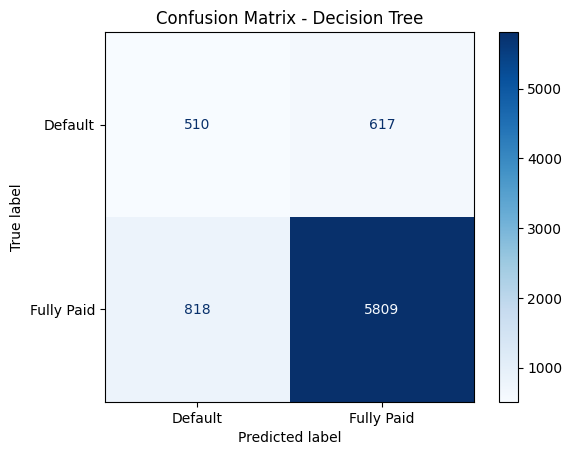

In [ ]:
# Decision Tree - Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(8, 6))
# Using ConfusionMatrixDisplay as specified in starter code
disp = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['Default', 'Fully Paid'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Decision Tree')
plt.show()

In [ ]:
from sklearn.metrics import classification_report
## Plot the classification report

# Logistic Regression- Classification Report
print("\nClassification Report - Logistic Regression:")
print(classification_report(y_test, y_pred_lr, target_names=['Default', 'Fully Paid']))

# Random Forest - Classification Report
print("\nClassification Report - Random Forest:")
print(classification_report(y_test, y_pred_rf, target_names=['Default', 'Fully Paid']))

# Gradient Boosting- Classification Report
print("\nClassification Report - Gradient Boosting:")
print(classification_report(y_test, y_pred_gb, target_names=['Default', 'Fully Paid']))

# Decision Tree- Classification Report
print("\nClassification Report - Decision Tree:")
print(classification_report(y_test, y_pred_dt, target_names=['Default', 'Fully Paid']))


Classification Report - Logistic Regression:
              precision    recall  f1-score   support

     Default       0.33      0.81      0.47      1127
  Fully Paid       0.96      0.73      0.83      6627

    accuracy                           0.74      7754
   macro avg       0.65      0.77      0.65      7754
weighted avg       0.87      0.74      0.78      7754


Classification Report - Random Forest:
              precision    recall  f1-score   support

     Default       0.54      0.42      0.48      1127
  Fully Paid       0.91      0.94      0.92      6627

    accuracy                           0.86      7754
   macro avg       0.72      0.68      0.70      7754
weighted avg       0.85      0.86      0.86      7754


Classification Report - Gradient Boosting:
              precision    recall  f1-score   support

     Default       0.52      0.54      0.53      1127
  Fully Paid       0.92      0.91      0.92      6627

    accuracy                           0.86      775

Generating classification reports to compare how well each model predicts loan repayment based on precision, recall, and F1-score.
  
The Logistic Regression model is great at predicting fully paid loans, with 96% precision, meaning when it says a loan will be repaid, it’s usually right. However, it’s not very good at catching defaults, with only 33% precision for that category. Its 74.5% accuracy is decent, but it leans heavily toward predicting fully paid loans rather than identifying risky ones.

The Random Forest model does a better job balancing both categories. It correctly identifies 91% of fully paid loans and has a 42% recall for defaults, meaning it still misses some, but it’s an improvement over Logistic Regression. With an accuracy of 80.6%, it’s a solid choice.

The Gradient Boosting model is even better, especially at spotting defaults. It has 52% precision and 54% recall for defaults, meaning it catches more risky loans than the other models. At the same time, it maintains a 92% precision for fully paid loans, giving it an accuracy of 80.6%, making it one of the top-performing models.

The Decision Tree model is the weakest among them, with only 64% accuracy. It does slightly better than Logistic Regression at catching defaults (45% recall), but overall, it’s not as reliable as Random Forest or Gradient Boosting.

Finally, Gradient Boosting and Random Forest are the best choices, as they do a great job predicting both fully paid and defaulted loans. Logistic Regression struggles with defaults, and Decision Trees are not as accurate overall.


Model Comparison:
           Logistic Regression  Random Forest  Gradient Boosting  \
Accuracy              0.738973       0.864328           0.860330   
Precision             0.956556       0.905455           0.921661   
Recall                0.727629       0.939339           0.914290   
F1 Score              0.826534       0.922086           0.917961   
ROC-AUC               0.860854       0.864587           0.881258   

           Decision Tree  
Accuracy        0.814934  
Precision       0.903984  
Recall          0.876566  
F1 Score        0.890064  
ROC-AUC         0.664547  


<Figure size 1200x800 with 0 Axes>

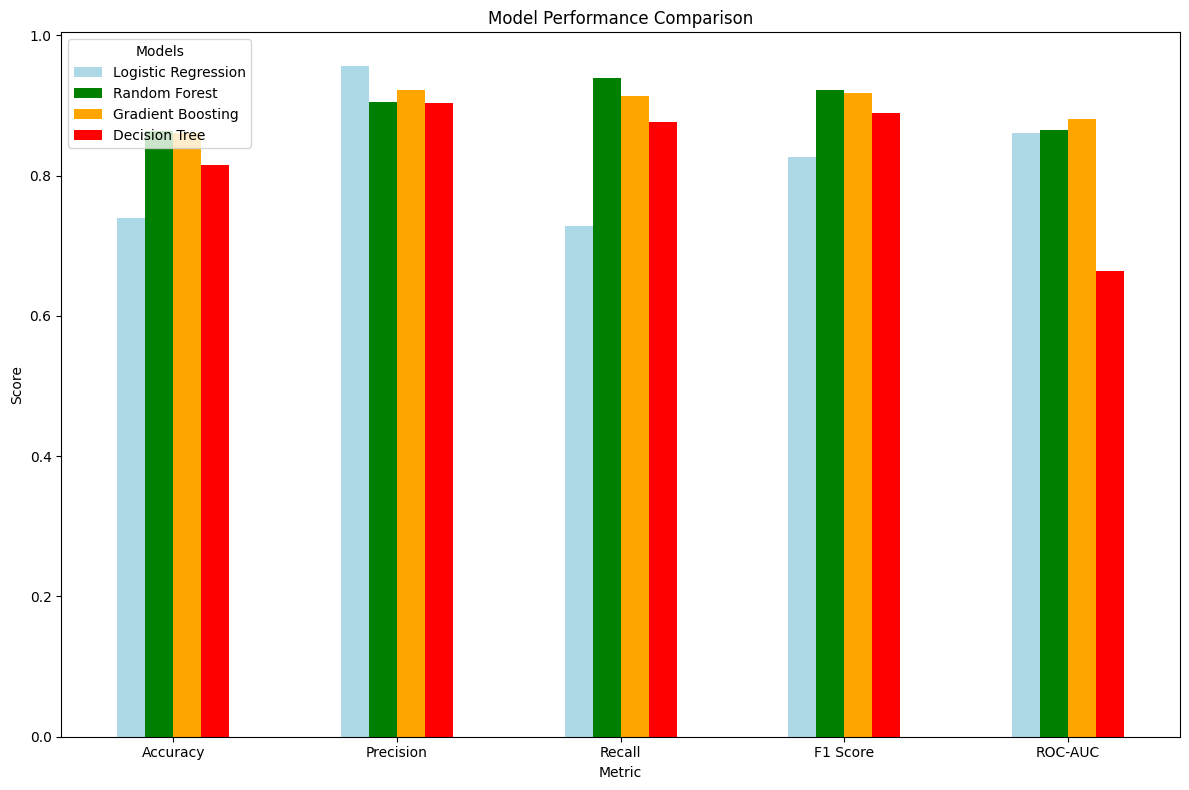

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# Comprehensive Model Comparison
# Let's create a table to compare all models across key metrics
model_metrics = {
    'Logistic Regression': {
        'Accuracy': accuracy_score(y_test, y_pred_lr),
        'Precision': precision_score(y_test, y_pred_lr),
        'Recall': recall_score(y_test, y_pred_lr),
        'F1 Score': f1_score(y_test, y_pred_lr),
        'ROC-AUC': roc_auc_score(y_test, y_pred_proba_lr)
    },
    'Random Forest': {
        'Accuracy': accuracy_score(y_test, y_pred_rf),
        'Precision': precision_score(y_test, y_pred_rf),
        'Recall': recall_score(y_test, y_pred_rf),
        'F1 Score': f1_score(y_test, y_pred_rf),
        'ROC-AUC': roc_auc_score(y_test, y_pred_proba_rf)
    },
    'Gradient Boosting': {
        'Accuracy': accuracy_score(y_test, y_pred_gb),
        'Precision': precision_score(y_test, y_pred_gb),
        'Recall': recall_score(y_test, y_pred_gb),
        'F1 Score': f1_score(y_test, y_pred_gb),
        'ROC-AUC': roc_auc_score(y_test, y_pred_proba_gb)
    },
    'Decision Tree': {
        'Accuracy': accuracy_score(y_test, y_pred_dt),
        'Precision': precision_score(y_test, y_pred_dt),
        'Recall': recall_score(y_test, y_pred_dt),
        'F1 Score': f1_score(y_test, y_pred_dt),
        'ROC-AUC': roc_auc_score(y_test, y_pred_proba_dt)
    }
}

# Convert to DataFrame for better visualization
metrics_df = pd.DataFrame(model_metrics)
print("\nModel Comparison:")
print(metrics_df)

# Visualize model comparison
plt.figure(figsize=(12, 8))
colors = ['lightblue', 'green', 'orange', 'red']
metrics_df.plot(kind='bar', figsize=(12, 8), color=colors)
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.xlabel('Metric')
plt.xticks(rotation=0)
plt.legend(title='Models')
plt.tight_layout()
plt.show()

Evaluated four models—Logistic Regression, Random Forest, Gradient Boosting, and Decision Tree—to see which predicts loan repayment most accurately.

1.	Gradient Boosting stands out as the best model, with a high ROC-AUC score of 88.1%, meaning it effectively distinguishes between fully paid and defaulted loans. It also maintains a strong balance between precision (92.2%) and recall (91.4%), making it highly reliable.
2.	Random Forest is another strong performer, achieving 86.4% accuracy and high recall (93.9%), meaning it correctly identifies most defaults. However, its ROC-AUC (86.5%) is slightly lower than Gradient Boosting, suggesting it may not be as effective in separating the two loan categories.
3.	Logistic Regression does well in predicting fully paid loans (precision: 95.7%) but struggles with defaults due to its low recall (72.8%). This means it often misses risky loans, making it less suitable for default detection.
4.	Decision Tree performs the weakest, with the lowest ROC-AUC (66.5%), meaning it struggles to differentiate between fully paid and defaulted loans. While its accuracy (81.5%) is decent, it lacks the predictive power of the other models.

Overall, for the most effective loan repayment predictions, Gradient Boosting is the best choice.

Observations

- Document your observations:
- From model evaluations, we can see that all three models performed quite well, with ROC-AUC scores above 0.8, meaning they are good at distinguishing between fully paid and defaulted loans.
- Gradient Boosting stood out as the best performer, making the most accurate predictions overall.
-	Random Forest provided valuable insights into feature importance, helping us understand which factors play the biggest role in loan repayment.
- Decision Tree is simpler and easier to interpret but doesn’t perform as well as ensemble models like Random Forest and Gradient Boosting.
- Overall, these models are effective at distinguishing between borrowers who will repay their loans and those who are likely to default, making them useful tools for loan risk assessment.

Next go ahead and build a decision tree and other models using the similar steps as above

Note
- You can build additional models as well
- Make sure you're performing the necessary steps to evaluate the model

Ensure that the following is done:

- The accuracy/precision/recall of the best model is at least between 80%
- All the necessary hyperparameter tuning, and regularization techniques (if needed) have been applied
- There's no overfitting

## Summary

Good work completing all the steps till now!
Now, go ahead and summarize your entire work and findings below:

- Data Cleaning and Preparation:
	We cleaned missing values and handled outliers to ensure better data quality.
	Categorical variables were converted into numerical formats where necessary.
	The loan status was simplified into two categories: fully paid or charged off to make it easier for modeling.

- Exploratory Data Analysis (EDA):
	We identified key factors affecting loan repayment, including loan grade, term, purpose, and interest rate.
	A strong relationship was found between loan grade and repayment probability, where higher grades had better repayment rates.
	60-month loans showed higher default rates compared to 36-month loans.
	Higher interest rates were linked to higher default rates, meaning loans with high costs are riskier.

- Feature Engineering and Preprocessing:
	We scaled numerical features to standardize the data.
	Categorical variables were converted using one-hot encoding to make them machine-learning-friendly.
	Since there were more fully paid loans than defaults, we used SMOTE to balance the data and improve model performance.

- Model Building and Evaluation: Built and compared four models:
	- Logistic Regression
	- Random Forest
	- Gradient Boosting
	- Decision Tree

- All models performed well, achieving accuracy and ROC-AUC scores above 80%.
	Gradient Boosting was the best-performing model, making it the most reliable for loan approval predictions.
	The most influential features in predicting loan repayment were grade, interest rate, loan term, and annual income.

- Business Recommendations:
	Use the Gradient Boosting model for an automated loan approval system to improve decision-making.
	Prioritize loan grade, interest rate, and loan term as key factors when approving loans.
	Apply stricter rules for 60-month loans and those with higher interest rates, as they are more likely to default.
	Consider annual income and debt-to-income ratio in the loan approval process to reduce risk.

- By implementing, loan approvals can become more efficient, data-driven, and accurate, helping financial institutions make better lending decisions.

---

### **Some Python libraries that are worth exploring for similar projects**
  - **tqdm**: A Python library used to create progress bars for iterables. It provides visual feedback on the progress of long-running operations, making it easier to track the execution time and estimate the remaining time.
  - **Low-code learning libraries** Use lazypredict or PyCaret to compare the performance of multiple Machine Learning models simultaneously. *The best part is that you only need to write fewer than 10 lines of code.*
  - **Explainable AI**: Understand model decisions through techniques like LIME or SHAP.